# Latent tasks
Latent arithmetic on one trained run (`decres-rescale-aug10-v1`): can we build the latent of a recording we never looked at from latents of other recordings? This is a clean redo of the nb139 analogies.

**Combine objects.** ½ · (obj1 at p1) + ½ · (obj2 at p2) + c = (obj1 + obj2 at p1, p2), where the *mean interaction* c = mean pair − ½ (mean obj1 + mean obj2).

**Swap objects.** (obj1 at p) − mean obj1 + mean obj2 = (obj2 at p).

All means come from one (box, speaker) group, use single-object recordings, and leave the target out.

**Notation.** z = latent of the true target recording, ẑ = predicted latent (the left-hand side), *predicted image* Î = decoder(ẑ) > 0.08, *true image* I = the target's label mask.

**Ranks.** The candidates are the target object's recordings in the same box and speaker. rank = 1 + the number of wrong candidates that score better than the truth.
- **exact** (the main number): only the target is true; the other recordings at the target's position (≤ 2 px) are dropped.
- **any** (nb139's rule): every recording at the target's position counts as true.

**Outline.**
1. Setup: paths, data constants, figure style.
2. Model, encode everything once (cached), decode, 2-D PCA.
3. Tasks: `combine_objects` and `swap_objects` build a `Task` (its `Term`s and ẑ).
4. Scoring: `search(task)` scores every task instance → one table; `summary`, `top_results`, `print_recordings`.
5. Drawing helpers, then `plot_equation`, `plot_equation_decoded`, `plot_pca`, `plot_layouts`.
6. Results: the top 3 of each task and the nb139 sample, the paper equations, the findings.

## Setup: imports, paths, constants, font

In [1]:
import functools, itertools, json, os, shutil, sys
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())  # repo root, wherever the notebook runs
sys.path.insert(0, str(ROOT / "src9"))

Run and cache paths.

In [2]:
RUN = os.environ.get("RUN", "decres-rescale-aug10-v1")  # the trained run to analyse
CACHE = ROOT / "runs/_src9_cache/nb141" / RUN           # latents, masks, metadata, PCA and search tables
HERE = ROOT / "figures/src/latent_tasks"                # this notebook's folder: the paper figures go here
FIG_DIR = HERE / "plots"                                # every per-result plot: <name>_<kind>.svg
CACHE.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

Data constants.

In [3]:
MASK_THRESHOLD = 0.08                            # decoder output > this = object pixel
SAME_POSITION_PX = 2.0                           # two recordings closer than this (px, 64×64 frame) are "at the same position"
LEFT_OUT_SPLITS = "shifted|unseen-speaker|lid"   # splits the tasks never use
OBJECTS = ["red-cube", "soap dispenser", "candle", "vase"]  # the single objects used by swap
PAIRS = {  # pair recording → (object used for the part, instance mask name) for part 0 and part 1
    "red-cube+vase": [("red-cube", "red-cube0"), ("vase", "vase0")],
    "green-cube+red-cube": [("red-cube", "green-cube0"), ("red-cube", "red-cube0")],  # no green-cube singles: a red cube stands in
}
BOXES = {  # experiment folder → short box name
    "2026_09_27_gastronorm_four_objs": "gastro",
    "2026_10_05_green_plastic_four_objs": "plastic",
    "2026_10_11_cardboard_four_objs": "cardboard",
}

Figure style.

In [4]:
font_manager.fontManager.addfont(str(ROOT / "assets/fonts/latinmodern-math.otf"))
plt.rcParams.update({
    "font.family": "Latin Modern Math",
    "mathtext.fontset": "custom",
    "mathtext.rm": "Latin Modern Math",
    "mathtext.it": "Latin Modern Math:italic",
    "mathtext.bf": "Latin Modern Math:bold",
    "svg.fonttype": "none",  # keep text as editable <text> in the SVGs (the viewer needs Latin Modern Math installed)
})

PRED_COLOUR = "#E6A700"                                           # the prediction ẑ / Î
TERM_COLOURS = ["tab:red", "tab:blue", "tab:purple", "tab:green"]  # PCA arrows, one per term
LATENT_CELLS = ["#e3f1f3", "#7fbfca", "#e3f1f3", "#b9dde3", "#4f9fae",
                "#e3f1f3", "#b9dde3", "#7fbfca", "#e3f1f3", "#b9dde3"]  # cell shades of z_latent in figure_model_arch
LATENT_SLOT_WIDTH = 0.45                                          # width of the latent-column slot, relative to a picture
OPERATOR_FS, TITLE_FS, LOCATION_FS = 40, 24, 17                   # + − = signs · title above a picture · object locations
PRED_TITLE, TRUE_TITLE = "predicted\nimage", "true\nimage"
SHORT_NAME = {"red-cube": "cube", "soap dispenser": "soap", "vase": "vase", "candle": "candle"}
ICON_FILE = {"red-cube": "cube", "vase": "vase", "candle": "candle", "soap dispenser": "soap"}  # assets/objects/individual/<name>.png
FIG_NAME = {"combine": "combine_objects", "swap": "swap_objects"}  # figure file prefix per task

## Model: Transformer4 from args.json, latest checkpoint, eager fp32 (torch.compile's no_grad eval gave wrong masks)

In [5]:
@functools.cache
def load_model():
    from dataset import build_dataset
    from arch.transformer4 import Transformer4
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    args = json.load(open(ROOT / "runs" / RUN / "args.json"))
    assert args["model"] == "transformer4", args["model"]
    _, eval_sets, train_set, info = build_dataset(args.get("window", "tukey"), num_workers=0)
    model = Transformer4(info, decoder=args.get("decoder", "two"), latent_norm=args.get("latent_norm", "ln"),
                         freq_rope=args.get("freq_rope", "linear"), spk_grl_w=args.get("spk_grl_w") or 0,
                         adapter_dim=args.get("adapter_dim") or 0)
    checkpoint = torch.load(ROOT / "runs" / RUN / "checkpoints/latest-rank0.pt", map_location="cpu", weights_only=False)
    print(model.load_state_dict(checkpoint["state"]["model"]))
    splits = [("train", train_set.dataloader.dataloader.dataset)]  # (split name, torch Subset)
    splits += [(e.label, e.dataloader.dataloader.dataset) for e in eval_sets]
    return model.cuda().eval(), splits

## Encode everything once → latents.npy, masks_pred.npy, masks_gt.npy, meta.parquet

In [6]:
def center_of_mass(mask):
    """(x, y) = (column, row) centre of a 64×64 mask, nan if empty."""
    rows, cols = np.nonzero(mask)
    if len(rows) == 0:
        return np.nan, np.nan
    return cols.mean(), rows.mean()

def part_center(sample_dir, instance):
    """One object's centre inside a pair recording, from its full-resolution instance mask, in 64×64 pixels."""
    mask = np.load(Path(sample_dir) / f"image/smasks/{instance}.npy") > 0
    rows, cols = np.nonzero(mask)
    x = (cols.mean() + .5) * 64 / mask.shape[1] - .5
    y = (rows.mean() + .5) * 64 / mask.shape[0] - .5
    return x, y

def encode_jobs(model, jobs, batch_size=128):
    """Run the model over (split, dataset, index) jobs → latents, model masks, true masks, metadata rows."""
    latents, model_masks, true_masks, rows = [], [], [], []
    with torch.no_grad():
        for start in range(0, len(jobs), batch_size):
            batch = jobs[start:start + batch_size]
            samples = [dataset[i] for _, dataset, i in batch]
            out = model(dict(fft=torch.stack([s["fft"] for s in samples]).cuda()))
            latents.append(out["latent"].float().cpu().numpy())
            model_masks.append(out["mask_pred"].float().cpu().numpy())
            true_masks.append(np.stack([(s["mask_true"] > .5).numpy() for s in samples]).astype(np.uint8))
            for split, dataset, i in batch:
                m = dataset.metas[i]
                rows.append(dict(split=split, box=BOXES[m["experiment"]], object="+".join(sorted(m["objects"])) or "empty",
                                 speaker=int(m["speaker"]), pos=int(m["position_id"]),
                                 dir=str(ROOT / "experiments" / m["experiment"] / "samples" / m["sample_id"])))
            if start % (20 * batch_size) == 0:
                print(f"{start}/{len(jobs)}", flush=True)
    return np.concatenate(latents), np.concatenate(model_masks), np.concatenate(true_masks), rows

def build_meta(rows, true_masks):
    meta = pd.DataFrame(rows)
    meta.index.name = "row"
    meta["sid"] = meta.pos.astype(str) + "-" + meta.speaker.astype(str)  # sample id = position-speaker
    meta[["x", "y"]] = [center_of_mass(m) for m in true_masks]
    meta["area"] = true_masks.sum((1, 2))
    meta["photo"] = meta.dir + "/image/02_cropped_overhead.png"
    for pair, parts in PAIRS.items():  # pairs also get each part's centre: x0, y0, x1, y1
        pair_rows = meta.index[meta.object == pair]
        for j, (_, instance) in enumerate(parts):
            meta.loc[pair_rows, [f"x{j}", f"y{j}"]] = [part_center(d, instance) for d in meta.dir[pair_rows]]
    return meta

def encode_all():
    if (CACHE / "meta.parquet").exists():
        return pd.read_parquet(CACHE / "meta.parquet"), np.load(CACHE / "latents.npy")
    model, splits = load_model()
    jobs = [(split, subset.dataset, i) for split, subset in splits for i in subset.indices]
    latents, model_masks, true_masks, rows = encode_jobs(model, jobs)
    meta = build_meta(rows, true_masks)
    np.save(CACHE / "latents.npy", latents)
    np.save(CACHE / "masks_pred.npy", model_masks)
    np.save(CACHE / "masks_gt.npy", true_masks)
    meta.to_parquet(CACHE / "meta.parquet")
    return meta, latents

## Decode: (N, 512) latents → soft masks, same fp32 path and batch size as the forward pass

In [7]:
def decode(latents, batch_size=128):
    decoder = load_model()[0].decoder
    masks = []
    with torch.no_grad():
        for start in range(0, len(latents), batch_size):
            batch = torch.from_numpy(np.ascontiguousarray(latents[start:start + batch_size], np.float32)).cuda()
            masks.append(decoder(batch).sigmoid().cpu().numpy())
    return np.concatenate(masks)

## 2-D PCA: fitted once on all latents, applied as x @ W without centring so tip-to-tail sums stay exact

In [8]:
def pca_2d(latents):
    path = CACHE / "pca2d.npz"
    if not path.exists():
        everything = np.load(CACHE / "latents.npy").astype(np.float64)
        mean = everything.mean(0)
        components = np.linalg.svd(everything - mean, full_matrices=False)[2][:2].T
        np.savez(path, W=components, mean=mean)
    return np.asarray(latents, np.float64) @ np.load(path)["W"]

## Load the caches (the first run encodes everything: a few minutes on the GPU)

In [9]:
META, LATENTS = encode_all()
TRUE_MASKS = np.load(CACHE / "masks_gt.npy", mmap_mode="r")
USABLE = META[~META.split.str.contains(LEFT_OUT_SPLITS)]  # the rows the tasks may use
print(len(META), "samples,", len(USABLE), "usable;", LATENTS.shape, LATENTS.dtype)
USABLE.groupby(["box", "object"]).size().unstack(0)

15891 samples, 15132 usable; (15891, 512) float32


box,cardboard,gastro,plastic
object,,,
biscoff,36.0,NaN,NaN
candle,1147.0,778.0,1011.0
coffee pot,36.0,24.0,343.0
cylinder-1000g,135.0,27.0,32.0
cylinder-100g,171.0,6.0,28.0
cylinder-200g,193.0,NaN,35.0
cylinder-500g,199.0,27.0,32.0
empty,73.0,36.0,60.0
glass-cup,120.0,NaN,NaN


## Check: decode(latents) reproduces the model's own mask_pred

In [10]:
model_masks = np.load(CACHE / "masks_pred.npy", mmap_mode="r")
error_same_batches = np.abs(decode(LATENTS[:1024]) - model_masks[:1024]).max()
random_rows = np.sort(np.random.default_rng(0).choice(len(LATENTS), 512, replace=False))
error_random_rows = np.abs(decode(LATENTS[random_rows]) - model_masks[random_rows]).max()
print(f"max |decode(latent) − mask_pred|: same batches {error_same_batches:.1e}, random rows {error_random_rows:.1e}")
# same batches: bit-exact; other batch compositions make cuDNN pick other conv algorithms (~1e-5)
assert error_same_batches == 0 and error_random_rows < 1e-4

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

<All keys matched successfully>


max |decode(latent) − mask_pred|: same batches 0.0e+00, random rows 1.3e-05


## Tasks: a `Term` is one summand of ẑ; a `Task` is one instance with its target and candidates

In [11]:
@dataclass
class Term:
    name: str           # e.g. "vase at p", "mean vase", "c"
    coef: float         # +1, −1 or ½
    latent: np.ndarray
    kind: str           # "photo" (one recording), "mean" (an object's mean latent) or "interaction" (the pair correction c)
    ref: object = None  # the recording's row for "photo", the object name for "mean"

@dataclass
class Task:
    task: str                 # "combine" or "swap"
    box: str
    speaker: int
    obj1: str
    obj2: str                 # the target's object
    target: int               # row of the true recording
    terms: list
    predicted_latent: np.ndarray
    cos_centre: np.ndarray    # cosines are taken around the leave-one-out mean of the target object
    candidates: pd.Index      # rows of the target object's recordings in the group
    same_position: np.ndarray  # which candidates sit at the target's position

def recordings_in(box, speaker):
    return USABLE[(USABLE.box == box) & (USABLE.speaker == speaker)]

def mean_latent(rows):
    return LATENTS[rows].mean(0)

def leave_one_out_mean(group, target):
    others = group.index[(group.object == META.object[target]) & (group.index != target)]
    return mean_latent(others)

def nearest_recording(recordings, x, y):
    distance = np.hypot(recordings.x - x, recordings.y - y)
    return distance.idxmin(), distance.min()

Candidates: the target object's recordings in the group, and which of them sit at the target's position (pairs: both parts within the radius).

In [12]:
def candidates(group, target):
    target_object = META.object[target]
    recordings = group[group.object == target_object]
    if target_object in PAIRS:
        centre_columns = [["x0", "y0"], ["x1", "y1"]]
    else:
        centre_columns = [["x", "y"]]
    distances = []
    for columns in centre_columns:
        offset = recordings[columns].values - META.loc[target, columns].values.astype(float)
        distances.append(np.hypot(offset[:, 0], offset[:, 1]))
    same_position = np.max(distances, 0) <= SAME_POSITION_PX
    return recordings.index, same_position

def make_task(task, group, target, obj1, terms, cos_centre):
    candidate_rows, same_position = candidates(group, target)
    predicted_latent = sum(term.coef * term.latent for term in terms)
    return Task(task, META.box[target], int(META.speaker[target]), obj1, META.object[target], target, terms,
                predicted_latent, cos_centre, candidate_rows, same_position)

Combine objects: ½ · (obj1 at p1) + ½ · (obj2 at p2) + c = the pair. Each part comes from the single recording nearest that part's centre.

In [13]:
def combine_objects(group, target):
    row = META.loc[target]
    (part0_object, _), (part1_object, _) = PAIRS[row.object]
    part0_recordings = group[group.object == part0_object]
    part1_recordings = group[group.object == part1_object]
    part0, _ = nearest_recording(part0_recordings, row.x0, row.y0)
    part1, _ = nearest_recording(part1_recordings, row.x1, row.y1)
    mean_pair = leave_one_out_mean(group, target)
    interaction = mean_pair - .5 * (mean_latent(part0_recordings.index) + mean_latent(part1_recordings.index))
    terms = [
        Term(f"{part0_object} at p1", .5, LATENTS[part0], "photo", part0),
        Term(f"{part1_object} at p2", .5, LATENTS[part1], "photo", part1),
        Term("c", 1., interaction, "interaction"),
    ]
    obj1 = row.object.split("+")[0]  # the first name in the pair label (green-cube for green-cube+red-cube)
    return make_task("combine", group, target, obj1, terms, cos_centre=mean_pair)

Swap objects: (obj1 at p) − mean obj1 + mean obj2 = obj2 at p. The source is the obj1 recording nearest p; no task if it is farther than the radius.

In [14]:
def swap_objects(group, target, obj1):
    row = META.loc[target]
    obj1_recordings = group[group.object == obj1]
    source, distance = nearest_recording(obj1_recordings, row.x, row.y)
    if distance > SAME_POSITION_PX:
        return None
    mean_target_object = leave_one_out_mean(group, target)
    terms = [
        Term(f"{obj1} at p", 1., LATENTS[source], "photo", source),
        Term(f"mean {obj1}", -1., mean_latent(obj1_recordings.index), "mean", obj1),
        Term(f"mean {row.object}", 1., mean_target_object, "mean", row.object),
    ]
    return make_task("swap", group, target, obj1, terms, cos_centre=mean_target_object)

Every instance of a task, group by group, and one instance rebuilt from its search-table row.

In [15]:
def all_instances(task):
    instances = []
    for (box, speaker), group in USABLE.groupby(["box", "speaker"]):
        if task == "combine":
            for target in group.index[group.object.isin(list(PAIRS))]:
                instances.append(combine_objects(group, target))
        else:
            for obj1 in OBJECTS:
                targets = group.index[group.object.isin(OBJECTS) & (group.object != obj1)]
                for target in targets:
                    instance = swap_objects(group, target, obj1)
                    if instance is not None:
                        instances.append(instance)
    return instances

def rebuild(row):
    group = recordings_in(row.box, row.speaker)
    if row.task == "combine":
        return combine_objects(group, row.target)
    return swap_objects(group, row.target, row.obj1)

## Scoring: distances in latent space and between layouts, and their ranks among the candidates

In [16]:
def unit(vectors):
    return vectors / np.linalg.norm(vectors, axis=-1, keepdims=True)

def rank_higher_better(scores, is_true):
    best_true = scores[is_true].max()
    return 1 + int((scores[~is_true] > best_true).sum())

def rank_lower_better(scores, is_true):
    best_true = scores[is_true].min()
    return 1 + int((scores[~is_true] < best_true).sum())

def iou(true_masks, mask):
    intersection = (true_masks & mask).sum((1, 2))
    union = (true_masks | mask).sum((1, 2))
    return intersection / np.maximum(union, 1)

def com_distance(rows, mask):
    """Distance from the mask's centre to each row's label centre; inf if the mask is empty."""
    offset = META.loc[rows, ["x", "y"]].values - center_of_mass(mask)
    return np.nan_to_num(np.hypot(offset[:, 0], offset[:, 1]), nan=np.inf)

Score one instance: compare ẑ with every candidate latent and Î with every candidate label.

In [17]:
def score(instance, predicted_mask, pred_index):
    candidate_rows = instance.candidates
    candidate_latents = LATENTS[candidate_rows]
    predicted = instance.predicted_latent
    is_target = candidate_rows.values == instance.target
    kept = ~instance.same_position | is_target  # exact rule: the other recordings at the target's position are dropped
    target_i = np.flatnonzero(is_target)[0]
    target_among_kept = is_target[kept]

    cos = unit(candidate_latents - instance.cos_centre) @ unit(predicted - instance.cos_centre)
    l2 = np.linalg.norm(candidate_latents - predicted, axis=1)
    l1 = np.abs(candidate_latents - predicted).sum(1)
    ious = iou(TRUE_MASKS[candidate_rows.values] > 0, predicted_mask)
    com = com_distance(candidate_rows, predicted_mask)

    photo_rows = [str(term.ref) for term in instance.terms if term.kind == "photo"]
    return dict(
        task=instance.task, box=instance.box, speaker=instance.speaker, obj1=instance.obj1, obj2=instance.obj2,
        target=instance.target, sid=META.sid[instance.target], term_rows=",".join(photo_rows),
        n_candidates=int(kept.sum()), n_candidates_any=len(candidate_rows),
        cos=cos[target_i], l2=l2[target_i], l1=l1[target_i], iou=ious[target_i], com=com[target_i],
        rank_cos=rank_higher_better(cos[kept], target_among_kept),
        rank_l2=rank_lower_better(l2[kept], target_among_kept),
        rank_l1=rank_lower_better(l1[kept], target_among_kept),
        rank_iou=rank_higher_better(ious[kept], target_among_kept),
        rank_com=rank_lower_better(com[kept], target_among_kept),
        rank_cos_any=rank_higher_better(cos, instance.same_position),
        rank_l2_any=rank_lower_better(l2, instance.same_position),
        pred_index=pred_index,
    )

Search: build every instance, decode all ẑ in one pass (Î saved as packed bits), score, and sort best first.

In [18]:
def predictions_path(task):
    return CACHE / f"search_v2_{task}_pred.npy"

def search(task):
    path = CACHE / f"search_v2_{task}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    instances = all_instances(task)
    predicted_masks = decode(np.stack([i.predicted_latent for i in instances])) > MASK_THRESHOLD
    np.save(predictions_path(task), np.packbits(predicted_masks.reshape(len(predicted_masks), -1), 1))
    table = pd.DataFrame([score(instance, predicted_masks[k], k) for k, instance in enumerate(instances)])
    table["rank1_cos_and_l2"] = (table.rank_cos == 1) & (table.rank_l2 == 1)
    table = table.sort_values(["rank1_cos_and_l2", "cos"], ascending=False).reset_index(drop=True)
    table.to_parquet(path)
    return table

def predicted_mask(row):
    bits = np.load(predictions_path(row.task), mmap_mode="r")[row.pred_index]
    return np.unpackbits(bits)[:4096].reshape(64, 64).astype(bool)

def true_mask(target):
    return TRUE_MASKS[target] > 0

Summary: rank@1 rates, mean IoU and median CoM distance per group of rows.

In [19]:
def rank1_fraction(ranks):
    return (ranks == 1).mean()

def summary(table, by=("box", "speaker")):
    return table.groupby(["task", *by]).agg(
        n=("target", "size"),
        cos_at1=("rank_cos", rank1_fraction),
        l2_at1=("rank_l2", rank1_fraction),
        cos_any_at1=("rank_cos_any", rank1_fraction),
        l2_any_at1=("rank_l2_any", rank1_fraction),
        l1_at1=("rank_l1", rank1_fraction),
        iou_at1=("rank_iou", rank1_fraction),
        mean_iou=("iou", "mean"),
        median_com=("com", "median"),
        n_cand=("n_candidates", "median"),
    ).round(3)

## Combine objects: every (box, speaker) group and pair recording

In [20]:
search_combine = search("combine")
display(search_combine.head(10))
display(summary(search_combine, by=("obj2", "box")))
summary(search_combine)

,task,box,speaker,obj1,obj2,target,sid,term_rows,n_candidates,n_candidates_any,...,com,rank_cos,rank_l2,rank_l1,rank_iou,rank_com,rank_cos_any,rank_l2_any,pred_index,rank1_cos_and_l2
0,combine,gastro,1,red-cube,red-cube+vase,2531,1217-1,"577,11309",42,42,...,5.398921,1,1,1,1,3,1,1,790,True
1,combine,gastro,1,red-cube,red-cube+vase,2544,1223-1,"236,1045",42,42,...,13.298337,1,1,1,1,25,1,1,795,True
2,combine,gastro,1,red-cube,red-cube+vase,11967,1219-1,"239,11345",42,42,...,2.055734,1,1,1,1,1,1,1,804,True
3,combine,gastro,7,red-cube,red-cube+vase,11969,1219-7,"241,11347",42,42,...,8.812114,1,1,1,2,6,1,1,1028,True
4,combine,gastro,1,green-cube,green-cube+red-cube,11991,1139-1,"595,236",72,72,...,3.538330,1,1,1,1,8,1,1,812,True
5,combine,gastro,7,red-cube,red-cube+vase,2532,1217-7,"579,11311",42,42,...,9.547773,1,1,1,1,6,1,1,1014,True
6,combine,gastro,7,red-cube,red-cube+vase,2456,1178-7,"591,11257",42,42,...,2.680125,1,1,1,1,2,1,1,988,True
7,combine,gastro,7,red-cube,red-cube+vase,2546,1223-7,"238,1047",42,42,...,12.819974,1,1,2,1,21,1,1,1019,True
8,combine,gastro,3,red-cube,red-cube+vase,2470,1188-3,"28,677",39,39,...,1.991478,1,1,1,1,3,1,1,882,True
9,combine,gastro,7,red-cube,red-cube+vase,2471,1188-7,"29,678",42,42,...,4.260271,1,1,1,1,4,1,1,993,True


n  cos_at1  l2_at1  cos_any_at1  \
task    obj2                box                                            
combine green-cube+red-cube cardboard  388    0.173   0.082        0.173   
                            gastro     215    0.544   0.423        0.544   
                            plastic    320    0.722   0.653        0.722   
        red-cube+vase       cardboard  317    0.479   0.360        0.479   
                            gastro     123    0.715   0.675        0.715   
                            plastic    140    0.964   0.893        0.964   

                                       l2_any_at1  l1_at1  iou_at1  mean_iou  \
task    obj2                box                                                
combine green-cube+red-cube cardboard       0.082   0.077    0.363     0.254   
                            gastro          0.433   0.414    0.502     0.302   
                            plastic         0.653   0.628    0.850     0.549   
        red-cube+vase       cardboard       0.360   0.328    0.637     0.452   
                            gastro          0.675   0.626    0.764     0.407   
                            plastic         0.893   0.879    0.943     0.594   

                                       median_com  n_cand  
task    obj2                box                            
combine green-cube+red-cube cardboard       7.498    98.0  
                            gastro          5.077    72.0  
                            plastic         2.537    80.0  
        red-cube+vase       cardboard       5.194    80.0  
                            gastro          5.399    42.0  
                            plastic         3.629    35.0

n  cos_at1  l2_at1  cos_any_at1  l2_any_at1  \
task    box       speaker                                                  
combine cardboard 1        178    0.399   0.281        0.399       0.281   
                  3        172    0.262   0.174        0.262       0.174   
                  5        177    0.288   0.153        0.288       0.153   
                  7        178    0.292   0.219        0.292       0.219   
        gastro    1        114    0.684   0.570        0.684       0.570   
                  3        110    0.473   0.391        0.473       0.400   
                  7        114    0.658   0.579        0.658       0.588   
        plastic   1        115    0.809   0.730        0.809       0.730   
                  3        115    0.800   0.774        0.800       0.774   
                  5        115    0.783   0.713        0.783       0.713   
                  7        115    0.791   0.687        0.791       0.687   

                           l1_at1  iou_at1  mean_iou  median_com  n_cand  
task    box       speaker                                                 
combine cardboard 1         0.275    0.624     0.407       5.889    98.0  
                  3         0.157    0.442     0.331       6.089    94.0  
                  5         0.136    0.452     0.326       6.456    98.0  
                  7         0.191    0.427     0.308       6.888    98.0  
        gastro    1         0.553    0.632     0.354       4.026    72.0  
                  3         0.382    0.564     0.324       5.964    71.0  
                  7         0.535    0.596     0.342       5.816    72.0  
        plastic   1         0.722    0.878     0.556       3.101    80.0  
                  3         0.757    0.904     0.577       2.264    80.0  
                  5         0.678    0.896     0.577       2.571    80.0  
                  7         0.661    0.835     0.540       3.156    80.0

## Swap objects: every (box, speaker) group, object pair and target recording

In [21]:
search_swap = search("swap")
display(search_swap.head(10))
display(summary(search_swap, by=("obj1", "obj2")))
summary(search_swap)

,task,box,speaker,obj1,obj2,target,sid,term_rows,n_candidates,n_candidates_any,...,com,rank_cos,rank_l2,rank_l1,rank_iou,rank_com,rank_cos_any,rank_l2_any,pred_index,rank1_cos_and_l2
0,swap,gastro,1,vase,soap dispenser,2083,1018-1,802,249,250,...,0.000000,1,1,1,1,1,1,1,13935,True
1,swap,gastro,7,red-cube,vase,861,479-7,546,218,218,...,1.762213,1,1,1,1,1,1,1,16478,True
2,swap,gastro,7,vase,red-cube,546,271-7,861,244,245,...,1.823288,1,1,1,1,1,1,1,18284,True
3,swap,gastro,7,vase,soap dispenser,2058,1005-7,840,249,251,...,1.081031,1,1,1,1,1,1,1,18537,True
4,swap,gastro,7,soap dispenser,vase,840,469-7,2058,217,218,...,1.207691,1,1,1,1,1,1,1,17249,True
5,swap,gastro,1,soap dispenser,vase,817,447-1,1808,219,219,...,0.604767,1,1,1,1,1,1,1,12634,True
6,swap,gastro,1,soap dispenser,vase,802,442-1,1841,217,219,...,0.967151,1,1,1,1,1,1,1,12632,True
7,swap,gastro,1,vase,soap dispenser,1841,913-1,802,248,250,...,1.051072,1,1,1,1,1,1,1,13871,True
8,swap,gastro,1,soap dispenser,vase,841,470-1,1805,218,219,...,0.818878,1,1,1,1,1,1,1,12640,True
9,swap,gastro,1,vase,soap dispenser,1805,900-1,841,249,250,...,0.503065,1,1,1,1,1,1,1,13862,True


n  cos_at1  l2_at1  cos_any_at1  \
task obj1           obj2                                                 
swap candle         red-cube        2055    0.112   0.120        0.214   
                    soap dispenser  3043    0.144   0.144        0.287   
                    vase            1544    0.172   0.185        0.262   
     red-cube       candle          2536    0.112   0.093        0.236   
                    soap dispenser  3204    0.214   0.198        0.348   
                    vase            2060    0.331   0.300        0.427   
     soap dispenser candle          2793    0.199   0.172        0.371   
                    red-cube        2571    0.261   0.259        0.410   
                    vase            2080    0.368   0.359        0.505   
     vase           candle          2084    0.165   0.147        0.336   
                    red-cube        2205    0.293   0.291        0.449   
                    soap dispenser  2839    0.269   0.276        0.461   

                                    l2_any_at1  l1_at1  iou_at1  mean_iou  \
task obj1           obj2                                                    
swap candle         red-cube             0.227   0.114    0.540     0.515   
                    soap dispenser       0.305   0.145    0.531     0.586   
                    vase                 0.284   0.177    0.551     0.647   
     red-cube       candle               0.202   0.091    0.462     0.669   
                    soap dispenser       0.312   0.195    0.498     0.575   
                    vase                 0.379   0.294    0.637     0.658   
     soap dispenser candle               0.330   0.174    0.661     0.740   
                    red-cube             0.412   0.254    0.683     0.569   
                    vase                 0.501   0.353    0.724     0.695   
     vase           candle               0.304   0.148    0.590     0.738   
                    red-cube             0.448   0.294    0.704     0.589   
                    soap dispenser       0.478   0.275    0.637     0.650   

                                    median_com  n_cand  
task obj1           obj2                                
swap candle         red-cube             1.625   251.0  
                    soap dispenser       1.477   302.0  
                    vase                 1.562   213.0  
     red-cube       candle               1.785   258.0  
                    soap dispenser       1.566   301.0  
                    vase                 1.445   214.0  
     soap dispenser candle               1.373   258.0  
                    red-cube             1.313   251.0  
                    vase                 1.241   213.0  
     vase           candle               1.456   258.0  
                    red-cube             1.243   251.0  
                    soap dispenser       1.214   301.0

n  cos_at1  l2_at1  cos_any_at1  l2_any_at1  \
task box       speaker                                                   
swap cardboard 1        2962    0.183   0.156        0.339       0.307   
               3        2905    0.122   0.099        0.265       0.228   
               5        2959    0.106   0.098        0.251       0.225   
               7        2965    0.143   0.120        0.284       0.255   
     gastro    1        2303    0.271   0.272        0.389       0.390   
               3        2306    0.207   0.212        0.332       0.345   
               7        2305    0.272   0.284        0.393       0.411   
     plastic   1        2569    0.302   0.290        0.438       0.432   
               3        2580    0.291   0.293        0.448       0.449   
               5        2582    0.279   0.276        0.435       0.432   
               7        2578    0.280   0.273        0.436       0.430   

                        l1_at1  iou_at1  mean_iou  median_com  n_cand  
task box       speaker                                                 
swap cardboard 1         0.152    0.565     0.617       1.555   302.0  
               3         0.096    0.483     0.584       1.709   294.0  
               5         0.099    0.490     0.583       1.733   302.0  
               7         0.120    0.494     0.581       1.769   301.0  
     gastro    1         0.270    0.604     0.634       1.448   248.0  
               3         0.212    0.590     0.625       1.498   248.0  
               7         0.281    0.603     0.627       1.469   249.0  
     plastic   1         0.286    0.695     0.687       1.192   250.0  
               3         0.291    0.704     0.687       1.190   250.0  
               5         0.268    0.701     0.685       1.181   251.0  
               7         0.275    0.701     0.688       1.193   251.0

## Picking results: the top k rows, one per set of recordings (a swap A → B and its mirror B → A use the same two recordings and tie)

In [22]:
def recording_set(row):
    return ",".join(sorted([str(row.target), *row.term_rows.split(",")]))

def top_results(table, k=3):
    keys = pd.Series([recording_set(row) for row in table.itertuples()], index=table.index)
    best = table[~keys.duplicated()].head(k).reset_index(drop=True)
    best["fig_name"] = [f"{FIG_NAME[task]}_{i + 1}" for i, task in enumerate(best.task)]
    return best

top_combine = top_results(search_combine)
top_swap = top_results(search_swap)
pd.concat([top_combine, top_swap])[["task", "box", "speaker", "obj1", "obj2", "sid", "term_rows", "cos", "rank_cos",
                                    "rank_cos_any", "iou", "rank_iou", "fig_name"]]

,task,box,speaker,obj1,obj2,sid,term_rows,cos,rank_cos,rank_cos_any,iou,rank_iou,fig_name
0,combine,gastro,1,red-cube,red-cube+vase,1217-1,"577,11309",0.854364,1,1,0.745614,1,combine_objects_1
1,combine,gastro,1,red-cube,red-cube+vase,1223-1,"236,1045",0.852293,1,1,0.435714,1,combine_objects_2
2,combine,gastro,1,red-cube,red-cube+vase,1219-1,"239,11345",0.845725,1,1,0.500000,1,combine_objects_3
0,swap,gastro,1,vase,soap dispenser,1018-1,802,0.898097,1,1,1.000000,1,swap_objects_1
1,swap,gastro,7,red-cube,vase,479-7,546,0.893726,1,1,0.632911,1,swap_objects_2
2,swap,gastro,7,vase,soap dispenser,1005-7,840,0.891618,1,1,0.617647,1,swap_objects_3


Every recording behind one result: sample id (position-speaker), speaker, box, object; each mean with its n (the target never counts).

In [23]:
def describe_recording(row_id):
    return f"{META.sid[row_id]} · spk {META.speaker[row_id]} · {META.box[row_id]} · {META.object[row_id]}"

def print_recordings(row):
    group = recordings_in(row.box, row.speaker)

    def count(obj):
        return int((group.object == obj).sum() - (obj == META.object[row.target]))

    for term in rebuild(row).terms:
        sign = ("−" if term.coef < 0 else "+") + (" ½" if abs(term.coef) == .5 else "")
        if term.kind == "photo":
            what = describe_recording(term.ref)
        elif term.kind == "mean":
            what = f"mean {term.ref} in {row.box} · spk {row.speaker} (n={count(term.ref)})"
        else:
            part0, part1 = (obj for obj, _ in PAIRS[row.obj2])
            what = (f"mean {row.obj2} (n={count(row.obj2)}) − ½(mean {part0} (n={count(part0)}) + mean {part1} (n={count(part1)}))"
                    f" in {row.box} · spk {row.speaker}")
        print(f"{sign:3s} {term.name:20s} {what}")
    print(f"{'=':3s} {'target':20s} {describe_recording(row.target)}")

## Drawing helpers: pictures, the latent column, masks, arrows, PCA axes, saving

In [24]:
@functools.cache
def load_rgba(path):
    image = Image.open(path).convert("RGBA")
    image.thumbnail((256, 256))
    return np.asarray(image)

def photo_image(row_id):
    return load_rgba(META.photo[row_id])

def icon_image(obj):
    return load_rgba(ROOT / f"assets/objects/individual/{ICON_FILE[obj]}.png")

def draw_photo(ax, row_id, outline=False):
    """A recording's photo stretched over the 64×64 mask frame (the frame spans the cropped photo), optionally its label outlined."""
    ax.imshow(photo_image(row_id), extent=(-.5, 63.5, 63.5, -.5), aspect="auto")
    if outline:
        ax.contour(true_mask(row_id), levels=[.5], colors="cyan", linewidths=2.5)

def draw_icon(ax, obj):
    """An object icon centred in a square, keeping its proportions."""
    image = icon_image(obj)
    height, width = image.shape[:2]
    side = max(height, width)
    ax.imshow(image, extent=((side - width) / 2, (side + width) / 2, (side + height) / 2, (side - height) / 2))
    ax.set_xlim(0, side)
    ax.set_ylim(side, 0)

def draw_frame(ax, colour, lw):
    ax.add_patch(Rectangle((-1.5, -1.5), 66, 66, fill=False, ec=colour, lw=lw, clip_on=False))

def draw_mask(ax, mask, colour="0.55", lw=1.2):
    ax.imshow(mask, cmap="gray", vmin=0, vmax=1)
    draw_frame(ax, colour, lw)

def draw_latent_column(ax):
    """A latent vector drawn like z_latent in the model diagram: one column of shaded cells, as tall as a picture."""
    n_cells = len(LATENT_CELLS)
    half_width = LATENT_SLOT_WIDTH * n_cells / 2  # the axes is LATENT_SLOT_WIDTH × as wide as tall
    ax.set_xlim(.5 - half_width, .5 + half_width)
    ax.set_ylim(n_cells, 0)
    ax.set_aspect("equal")
    for j, colour in enumerate(LATENT_CELLS):
        ax.add_patch(Rectangle((0, j), 1, 1, fc=colour, ec="#2f6f7a", lw=1.2))
    ax.add_patch(Rectangle((0, 0), 1, n_cells, fill=False, ec="#1f4f57", lw=2))

def draw_arrow(ax, start, end, colour, lw=2.2, ls="-", alpha=1., zorder=3):
    style = dict(arrowstyle="-|>", color=colour, lw=lw, ls=ls, alpha=alpha, shrinkA=0, shrinkB=0, mutation_scale=22)
    ax.annotate("", end, start, arrowprops=style, zorder=zorder)

def draw_pca_axes(ax, points, margin):
    """Axes through the origin, square limits (both axes get the larger span) that fit the points plus a margin."""
    low = np.minimum(points.min(0), 0) - margin
    high = np.maximum(points.max(0), 0) + margin
    middle, half_span = (low + high) / 2, (high - low).max() / 2
    low, high = middle - half_span, middle + half_span
    ax.set_xlim(low[0], high[0])
    ax.set_ylim(low[1], high[1])
    ax.set_aspect("equal")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_position("zero")
        ax.spines[side].set_color("0.6")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(high[0], 0, " PC1", va="center", fontsize=11)
    ax.text(0, high[1], "PC2", va="bottom", ha="center", fontsize=11)

def task_title(row):
    if row.task == "combine":
        return f"combine objects · {row.obj2}"
    return f"swap objects · {row.obj1} → {row.obj2}"

def save_figure(fig, row, kind):
    path = FIG_DIR / f"{row.fig_name}_{kind}.svg"
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return path

## Equation pictures: three slots per term (operator | coefficient | picture), then = | predicted image | divider | true image

In [25]:
def location(x, y):
    return f"({x:.0f}, {y:.0f})"

def term_title(term):
    if term.kind == "interaction":
        return "mean\ninteraction"
    if term.kind == "photo":
        return f"{SHORT_NAME[META.object[term.ref]]} at {location(META.x[term.ref], META.y[term.ref])}"
    return f"mean {SHORT_NAME[term.ref]}"

def true_objects(row):
    """(short name, x, y) of each object in the target recording."""
    target = META.loc[row.target]
    if row.obj2 in PAIRS:
        return [(SHORT_NAME[obj], target[f"x{j}"], target[f"y{j}"]) for j, (obj, _) in enumerate(PAIRS[row.obj2])]
    return [(SHORT_NAME[row.obj2], target.x, target.y)]

def blob_centers(mask):
    """(x, y) centre of each connected object in a mask, largest first."""
    labels, n = ndimage.label(mask)
    sizes = [(labels == k).sum() for k in range(1, n + 1)]
    order = np.argsort([-s for s in sizes]) + 1
    return [center_of_mass(labels == k) for k in order]

def true_locations_text(row):
    return "\n".join(f"{name} {location(x, y)}" for name, x, y in true_objects(row))

def predicted_locations_text(mask, row):
    """Each blob of the predicted mask, named after the nearest true object, in the true objects' order."""
    objects = true_objects(row)

    def nearest_object(x, y):
        distances = [np.hypot(ox - x, oy - y) for _, ox, oy in objects]
        return int(np.argmin(distances))

    blobs = sorted(blob_centers(mask), key=lambda xy: nearest_object(*xy))
    return "\n".join(f"{objects[nearest_object(x, y)][0]} {location(x, y)}" for x, y in blobs)

Figure skeleton and the shared right-hand side. The titles go above the tallest picture, with room for the location lines.

In [26]:
def equation_axes(slot_widths):
    """One row of axes: per term [operator, coefficient, picture], then [=, predicted, divider, true]."""
    n_terms = len(slot_widths)
    ratios = []
    for width in slot_widths:
        ratios += [.26, .3, width]
    ratios += [.26, 1, .08, 1]
    narrow_slot = any(width < 1 for width in slot_widths)
    fig_width = 3.2 * n_terms + 6.8 - (2.2 if narrow_slot else 0)  # the latent column frees about 2.2 in
    fig, axes = plt.subplots(1, len(ratios), figsize=(fig_width, 3.6), gridspec_kw=dict(width_ratios=ratios, wspace=.02))
    for ax in axes:
        ax.set_axis_off()
    return fig, axes

def draw_operators(axes, terms):
    for i, term in enumerate(terms):
        sign = "−" if term.coef < 0 else ("+" if i > 0 else "")
        axes[3 * i].text(.5, .5, sign, ha="center", va="center", fontsize=OPERATOR_FS)
        if abs(term.coef) == .5:  # Latin Modern Math has no ½ glyph
            axes[3 * i + 1].text(.5, .5, r"$\frac{1}{2}$", ha="center", va="center", fontsize=OPERATOR_FS * 1.15)

def draw_titles(fig, titles, locations):
    """titles: {axes: text above it}; locations: {axes: smaller lines just above the picture}."""
    fig.canvas.draw()
    boxes = {ax: ax.get_position() for ax in titles}
    top = max(box.y1 for box in boxes.values()) + .02
    max_lines = max(text.count("\n") + 1 for text in locations.values())
    location_height = max_lines * LOCATION_FS * 1.25 / 72 / fig.get_figheight()  # in figure fractions
    for ax, text in titles.items():
        centre_x = (boxes[ax].x0 + boxes[ax].x1) / 2
        fig.text(centre_x, top + location_height, text, ha="center", va="bottom", fontsize=TITLE_FS, linespacing=1.0)
        if ax in locations:
            fig.text(centre_x, top, locations[ax], ha="center", va="bottom", fontsize=LOCATION_FS, linespacing=1.1)

def finish_equation(fig, axes, row, titles):
    """= predicted image | true image, then all titles. titles holds the term pictures' titles."""
    n_terms = (len(axes) - 4) // 3
    equals, pred_ax, divider, true_ax = axes[3 * n_terms:]
    equals.text(.5, .5, "=", ha="center", va="center", fontsize=OPERATOR_FS)
    mask = predicted_mask(row)
    draw_mask(pred_ax, mask, PRED_COLOUR, 4)
    divider.axvline(.5, ymin=.05, ymax=.95, color="0.3", lw=1.5)
    draw_mask(true_ax, true_mask(row.target))
    for ax in (pred_ax, true_ax):
        ax.set_box_aspect(1)
    titles = {**titles, pred_ax: PRED_TITLE, true_ax: TRUE_TITLE}
    locations = {pred_ax: predicted_locations_text(mask, row), true_ax: true_locations_text(row)}
    draw_titles(fig, titles, locations)

The picture equation: photos for recordings, icons for means, the latent column for c.

In [27]:
def plot_equation(row, outline=False):
    terms = rebuild(row).terms
    slot_widths = [LATENT_SLOT_WIDTH if term.kind == "interaction" else 1 for term in terms]
    fig, axes = equation_axes(slot_widths)
    draw_operators(axes, terms)
    titles = {}
    for i, term in enumerate(terms):
        ax = axes[3 * i + 2]
        if term.kind == "interaction":
            draw_latent_column(ax)  # keeps its own narrow box, same height as the squares
        elif term.kind == "photo":
            draw_photo(ax, term.ref, outline)
            ax.set_box_aspect(1)
        else:
            draw_icon(ax, term.ref)
            ax.set_box_aspect(1)
        titles[ax] = term_title(term)
    finish_equation(fig, axes, row, titles)
    return save_figure(fig, row, "eqn")

The same equation with every term's latent run through the decoder.

In [28]:
def plot_equation_decoded(row):
    terms = rebuild(row).terms
    term_masks = decode(np.stack([term.latent for term in terms])) > MASK_THRESHOLD
    fig, axes = equation_axes([1] * len(terms))
    draw_operators(axes, terms)
    titles = {}
    for i, (term, mask) in enumerate(zip(terms, term_masks)):
        ax = axes[3 * i + 2]
        draw_mask(ax, mask)
        ax.set_box_aspect(1)
        titles[ax] = term_title(term)
    finish_equation(fig, axes, row, titles)
    return save_figure(fig, row, "eqn_decoded")

## PCA pictures: thumbnails next to the arrows

In [29]:
def pca_image(ax, centre, image, size):
    """An image fitted inside a size × size square around centre, keeping its proportions."""
    x, y = centre
    height, width = image.shape[:2]
    half_w = size / 2 * min(1, width / height)
    half_h = size / 2 * min(1, height / width)
    ax.imshow(image, extent=(x - half_w, x + half_w, y - half_h, y + half_h), zorder=5, interpolation="antialiased")

def pca_latent_column(ax, centre, size, n_cells=8):
    """The mean interaction: the same shaded latent column as in the equation."""
    x, y = centre
    cell = size / n_cells
    for j, colour in enumerate(LATENT_CELLS[:n_cells]):
        ax.add_patch(Rectangle((x - cell / 2, y + size / 2 - (j + 1) * cell), cell, cell, fc=colour, ec="#2f6f7a", lw=.8, zorder=5))
    ax.add_patch(Rectangle((x - cell / 2, y - size / 2), cell, size, fill=False, ec="#1f4f57", lw=1.4, zorder=6))

def pca_mask(ax, centre, mask, colour, size):
    """A layout in a coloured frame."""
    x, y = centre
    extent = (x - size / 2, x + size / 2, y - size / 2, y + size / 2)
    ax.imshow(mask, cmap="gray", vmin=0, vmax=1, extent=extent, zorder=5, interpolation="nearest")
    ax.add_patch(Rectangle((x - size / 2, y - size / 2), size, size, fill=False, ec=colour, lw=2.5, zorder=6))

def pca_term_picture(ax, centre, term, size):
    if term.kind == "interaction":
        pca_latent_column(ax, centre, size)
    elif term.kind == "photo":
        pca_image(ax, centre, photo_image(term.ref), size)
    else:
        pca_image(ax, centre, icon_image(term.ref), size)

Thumbnail placement: beside each arrow near its tip, perpendicular to it, on the side with more room; then pushed off overlaps.

In [30]:
def clearance(point, obstacles):
    """Chebyshev distance from point to the nearest obstacle point."""
    return np.abs(obstacles - point).max(1).min()

def push_apart(centres, obstacles, size, steps=300):
    """Push size × size thumbnails off each other and off the arrows, with a weak pull back to where they started."""
    start = centres.copy()
    for _ in range(steps):
        for i in range(len(centres)):
            for others, gap in ((np.delete(centres, i, 0), 1.05 * size), (obstacles, .55 * size)):
                offset = centres[i] - others
                distance = np.abs(offset).max(1)
                hit = distance < gap
                if hit.any():
                    direction = offset[hit] / (np.linalg.norm(offset[hit], axis=1, keepdims=True) + 1e-9)
                    centres[i] += .1 * ((gap - distance[hit])[:, None] * direction).sum(0)
            centres[i] += .05 * (start[i] - centres[i])
    return centres

def place_thumbnails(tips, segments, size, directions):
    obstacles = np.concatenate([np.linspace(start, end, 25) for start, end in segments])  # points along every arrow
    centres = []
    for tip, direction in zip(np.asarray(tips, float), np.asarray(directions, float)):
        length = np.linalg.norm(direction)
        along = direction / (length + 1e-9)
        normal = np.array([-along[1], along[0]])
        anchor = tip - min(.45 * size, .35 * length) * along  # a bit back from the tip, so the picture sits beside the head
        options = [anchor + side * .7 * size * normal for side in (1, -1)]
        taken = np.r_[obstacles, np.array(centres).reshape(-1, 2)]
        centres.append(max(options, key=lambda option: clearance(option, taken)))
    return push_apart(np.array(centres), obstacles, size)

def arrow_starts(vectors, gap):
    """All arrows start at the origin, except one nearly collinear with an earlier one: it is shifted sideways by gap."""
    starts = [np.zeros(2) for _ in vectors]
    for i, j in itertools.combinations(range(len(vectors)), 2):
        u = vectors[i] / np.linalg.norm(vectors[i])
        w = vectors[j] / np.linalg.norm(vectors[j])
        if abs(u @ w) > .98:
            starts[j] = starts[j] + gap * np.array([-w[1], w[0]])
    return starts

## plot_pca: the task in the shared 2-D PCA. Left: each term from the origin. Right: tip to tail → ẑ against z

In [31]:
def draw_terms_panel(ax, terms, vectors, all_points, size):
    starts = arrow_starts(vectors, .025 * size / .22)
    tips = [start + vector for start, vector in zip(starts, vectors)]
    centres = place_thumbnails(tips, list(zip(starts, tips)), size, vectors)
    longest_first = np.argsort([-np.linalg.norm(v) for v in vectors])  # long arrows thick and underneath
    for k, i in enumerate(longest_first):
        draw_arrow(ax, starts[i], tips[i], TERM_COLOURS[i], lw=3.6 - .9 * k, zorder=3 + k)
        pca_term_picture(ax, centres[i], terms[i], size)
    draw_pca_axes(ax, np.r_[all_points, centres], size * .6)
    ax.set_title("terms (from the origin)", fontsize=15, pad=14)

def draw_tip_to_tail_panel(ax, row, chain, predicted, true, all_points, size):
    for start, end, colour in zip(chain[:-1], chain[1:], TERM_COLOURS):
        draw_arrow(ax, start, end, colour, alpha=.35)
    draw_arrow(ax, (0, 0), true, PRED_COLOUR, lw=2.4, ls=(0, (4, 2.5)), zorder=4)
    ax.scatter(*true, s=110, facecolors="none", edgecolors=PRED_COLOUR, linewidths=2.2, zorder=6)
    draw_arrow(ax, (0, 0), predicted, PRED_COLOUR, lw=4, zorder=5)
    ax.scatter(*predicted, marker="*", s=520, c=PRED_COLOUR, edgecolors="0.15", linewidths=1.2, zorder=7)
    segments = [(np.zeros(2), predicted), (np.zeros(2), true)] + list(zip(chain[:-1], chain[1:]))
    true_centre, predicted_centre = place_thumbnails([true, predicted], segments, size, [true, predicted])
    pca_image(ax, true_centre, photo_image(row.target), size)                 # the true recording's photo by z
    pca_mask(ax, predicted_centre, predicted_mask(row), PRED_COLOUR, size)    # the decoded layout by ẑ
    draw_pca_axes(ax, np.r_[all_points, [true_centre, predicted_centre]], size * .6)
    ax.set_title("tip to tail", fontsize=15, pad=14)

def legend_label(term):
    sign = "− " if term.coef < 0 else "+ "
    half = r"$\frac{1}{2}$ · " if abs(term.coef) == .5 else ""  # Latin Modern Math has no ½ glyph
    name = "mean interaction" if term.kind == "interaction" else term.name
    return sign + half + name

def draw_legend_and_scores(ax, row, terms):
    handles = [Line2D([], [], color=colour, lw=2.5, label=legend_label(term)) for colour, term in zip(TERM_COLOURS, terms)]
    handles.append(Line2D([], [], color=PRED_COLOUR, lw=4, marker="*", ms=16, mec="0.15", label=r"$\hat{z}$ prediction"))
    handles.append(Line2D([], [], color=PRED_COLOUR, lw=2.4, ls=(0, (4, 2.5)), marker="o", mfc="none", ms=10,
                          label=f"z ground truth ({row.obj2} {row.sid})"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.1, 1), fontsize=12, frameon=False)
    cos_line = rf"cos$(z, \hat{{z}})$ = {row.cos:.2f}  (rank {row.rank_cos} of {row.n_candidates})"
    l1_line = rf"L1$(z, \hat{{z}})$ = {row.l1:.0f}  (rank {row.rank_l1} of {row.n_candidates})"
    ax.text(1.1, .05, cos_line + "\n" + l1_line, transform=ax.transAxes, fontsize=13, linespacing=1.7, va="bottom")

def plot_pca(row):
    instance = rebuild(row)
    terms = instance.terms
    vectors = [term.coef * pca_2d(term.latent) for term in terms]
    predicted = pca_2d(instance.predicted_latent)
    true = pca_2d(LATENTS[row.target])
    chain = np.cumsum([np.zeros(2)] + vectors, 0)  # tip-to-tail partial sums
    assert np.allclose(chain[-1], predicted, atol=1e-6 * np.abs(predicted).max())  # the chain ends at pca(ẑ)
    all_points = np.r_[vectors, chain, [predicted, true]]
    size = .22 * np.ptp(np.r_[all_points, [[0, 0]]], 0).max()  # thumbnail side: 22 % of the larger data span

    fig, (left, right) = plt.subplots(1, 2, figsize=(15, 6.2))
    draw_terms_panel(left, terms, vectors, all_points, size)
    draw_tip_to_tail_panel(right, row, chain, predicted, true, all_points, size)
    draw_legend_and_scores(right, row, terms)
    fig.suptitle(f"{task_title(row)} · {row.box} · spk {row.speaker}", fontsize=17, y=1.03)
    return save_figure(fig, row, "pca")

## plot_layouts: predicted image Î = decoder(ẑ) > 0.08 next to the true image I

In [32]:
def plot_layouts(row):
    fig, (pred_ax, true_ax) = plt.subplots(1, 2, figsize=(9, 5))
    pred_ax.imshow(predicted_mask(row), cmap="gray", vmin=0, vmax=1)
    pred_ax.set_title(r"$\hat{I}$ (prediction)", fontsize=15)
    true_ax.imshow(true_mask(row.target), cmap="gray", vmin=0, vmax=1)
    true_ax.set_title(r"$I$ (ground truth)", fontsize=15)
    for ax in (pred_ax, true_ax):
        ax.set_axis_off()
    draw_frame(pred_ax, PRED_COLOUR, 5)
    draw_frame(true_ax, "0.55", 1.2)
    iou_text = rf"IoU$(I, \hat{{I}})$ = {row.iou:.2f}  (rank {row.rank_iou} of {row.n_candidates})"
    com_text = f"CoM distance = {row.com:.1f} px  (rank {row.rank_com} of {row.n_candidates})"
    fig.text(.5, .02, iou_text + "      " + com_text, ha="center", fontsize=13)
    return save_figure(fig, row, "layouts")

# Results
The top 3 of each task → figures/src/latent_tasks/plots/<task>_<k>_{eqn,eqn_decoded,pca,layouts}.svg

### combine_objects_1

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


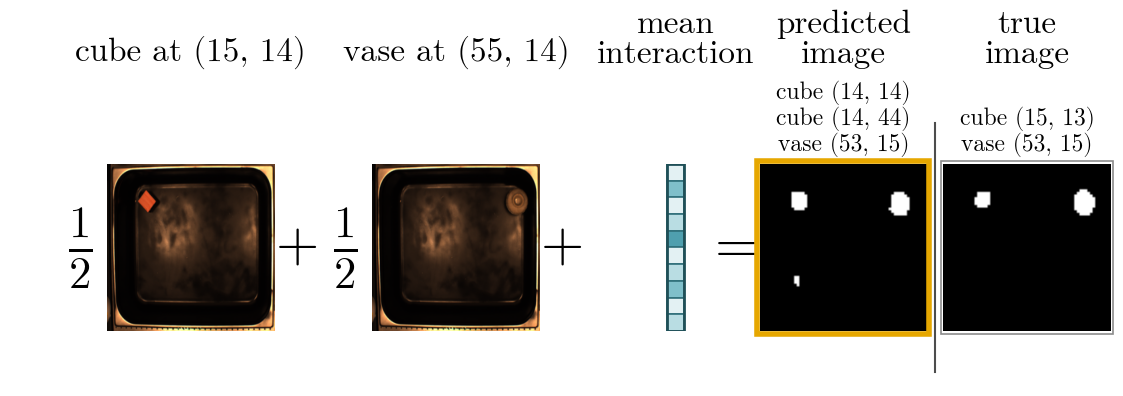

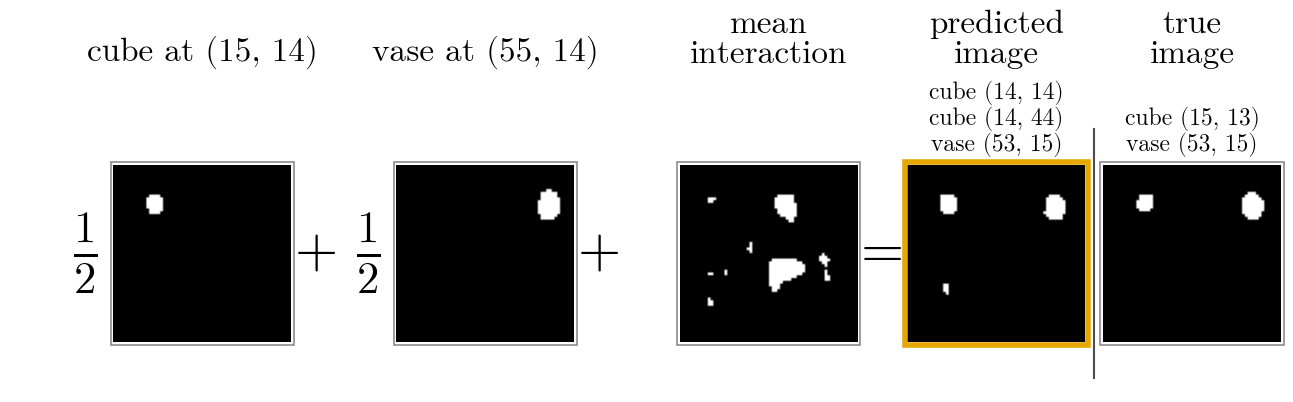

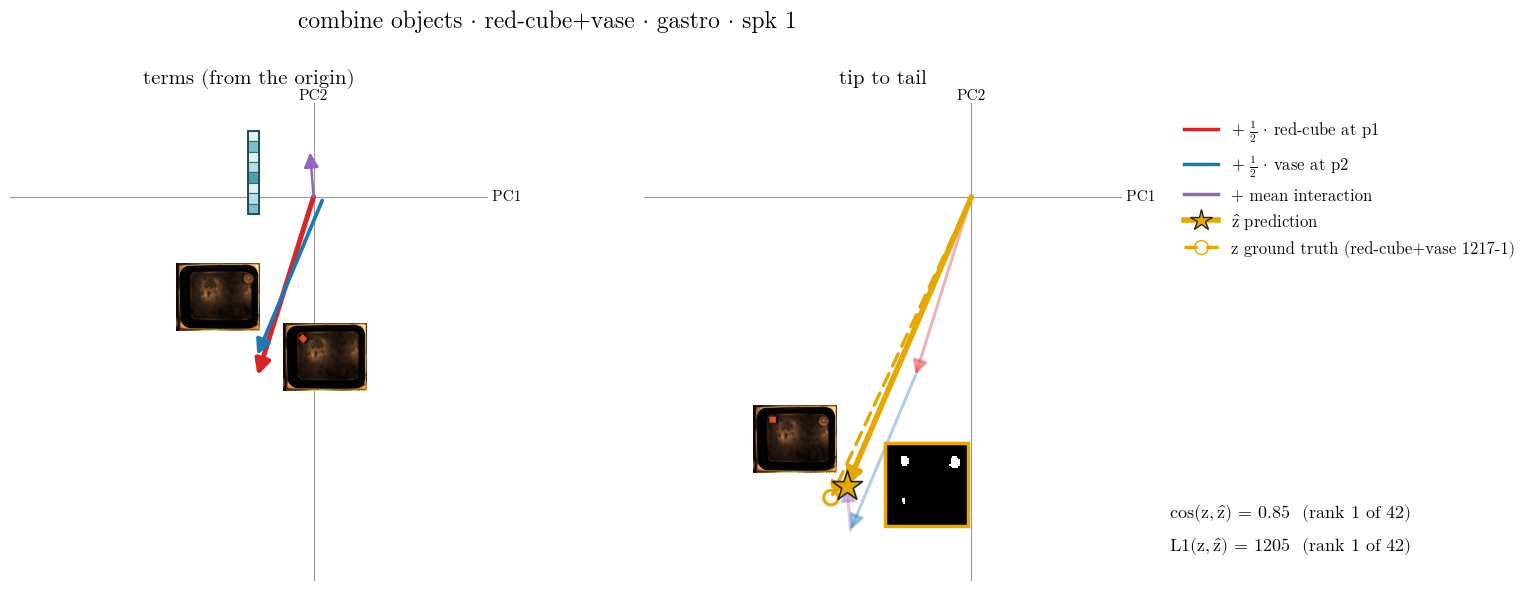

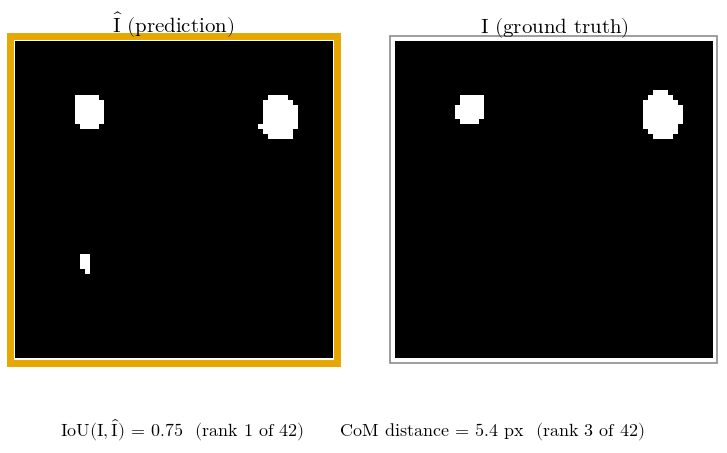

+ ½ red-cube at p1       284-1 · spk 1 · gastro · red-cube
+ ½ vase at p2           546-1 · spk 1 · gastro · vase
+   c                    mean red-cube+vase (n=41) − ½(mean red-cube (n=245) + mean vase (n=219)) in gastro · spk 1
=   target               1217-1 · spk 1 · gastro · red-cube+vase


In [33]:
row = top_combine.iloc[0]
plot_equation(row)
plot_equation_decoded(row)
plot_pca(row)
plot_layouts(row)
print_recordings(row)

### combine_objects_2

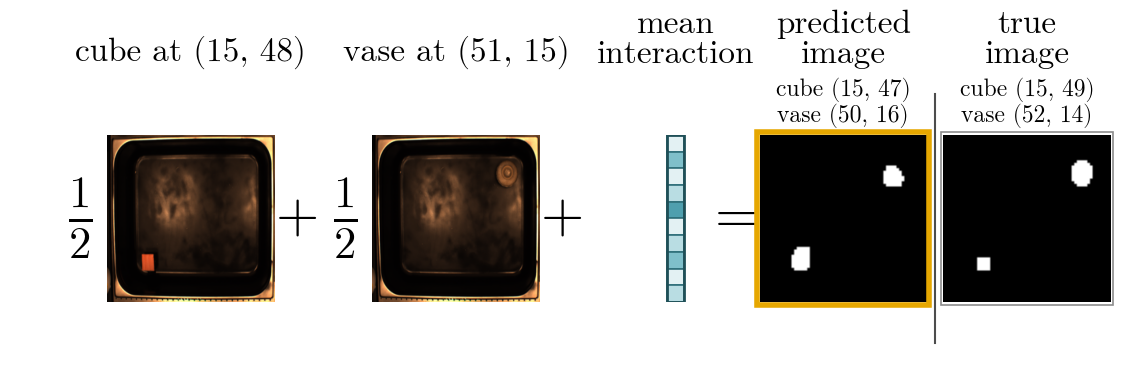

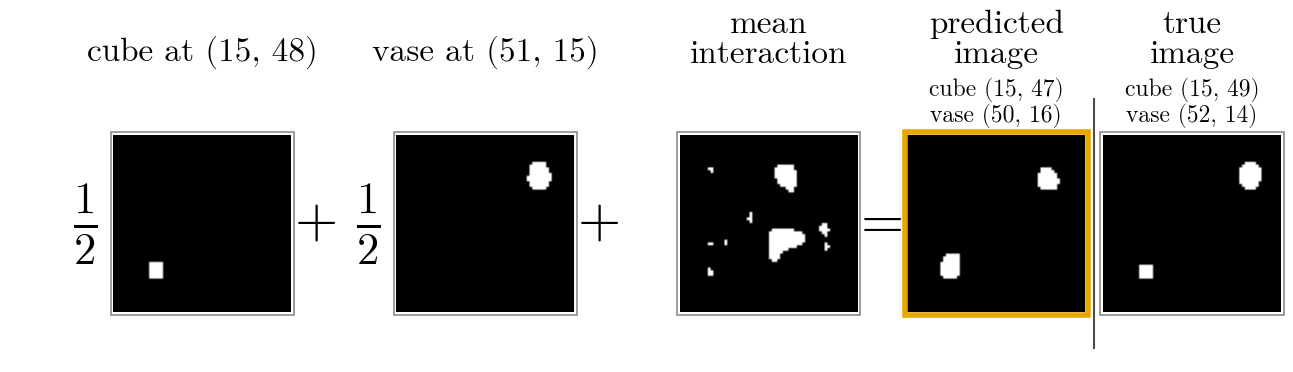

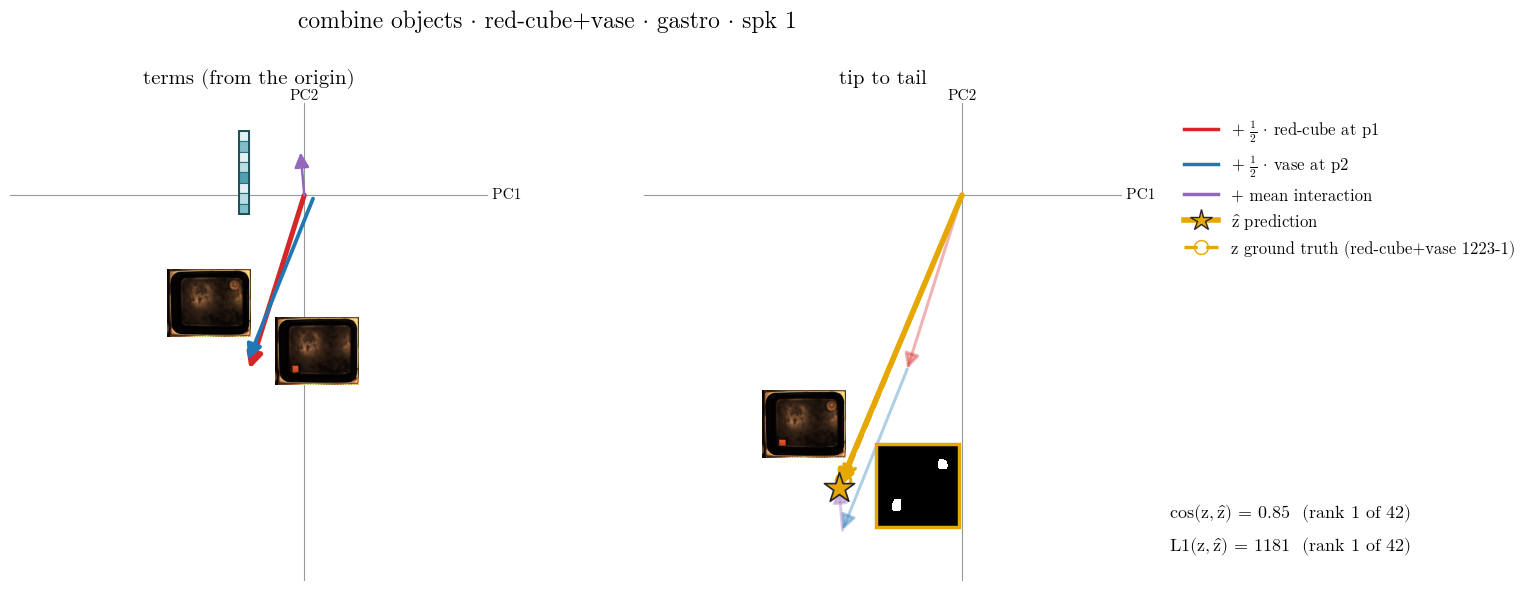

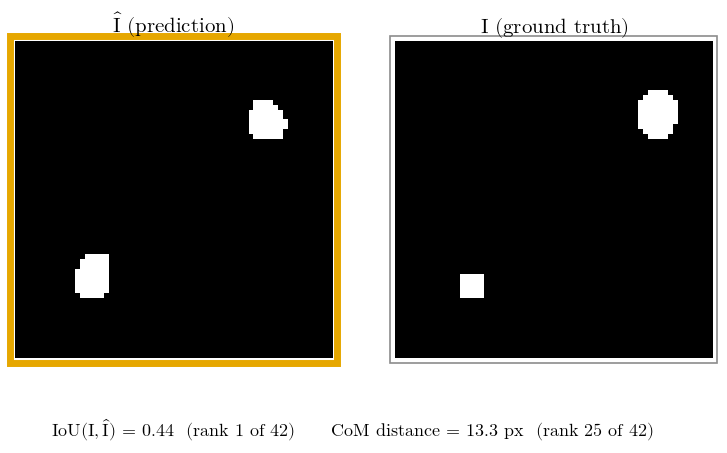

+ ½ red-cube at p1       117-1 · spk 1 · gastro · red-cube
+ ½ vase at p2           576-1 · spk 1 · gastro · vase
+   c                    mean red-cube+vase (n=41) − ½(mean red-cube (n=245) + mean vase (n=219)) in gastro · spk 1
=   target               1223-1 · spk 1 · gastro · red-cube+vase


In [34]:
row = top_combine.iloc[1]
plot_equation(row)
plot_equation_decoded(row)
plot_pca(row)
plot_layouts(row)
print_recordings(row)

### combine_objects_3

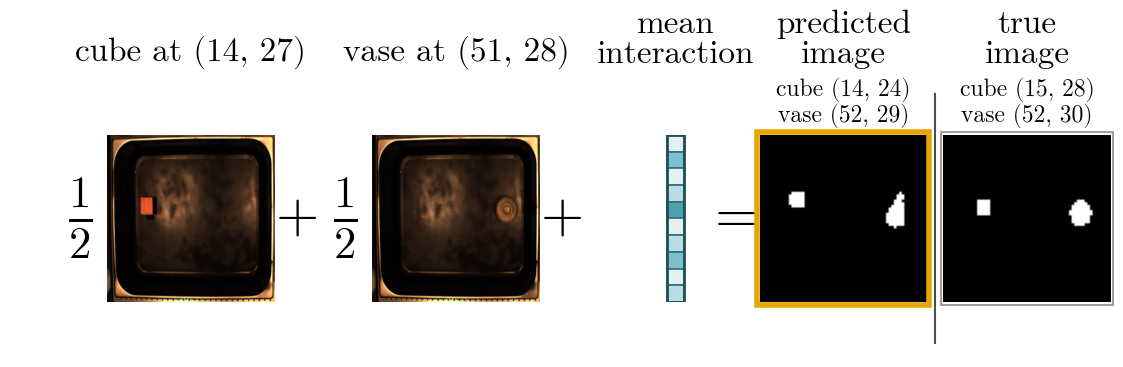

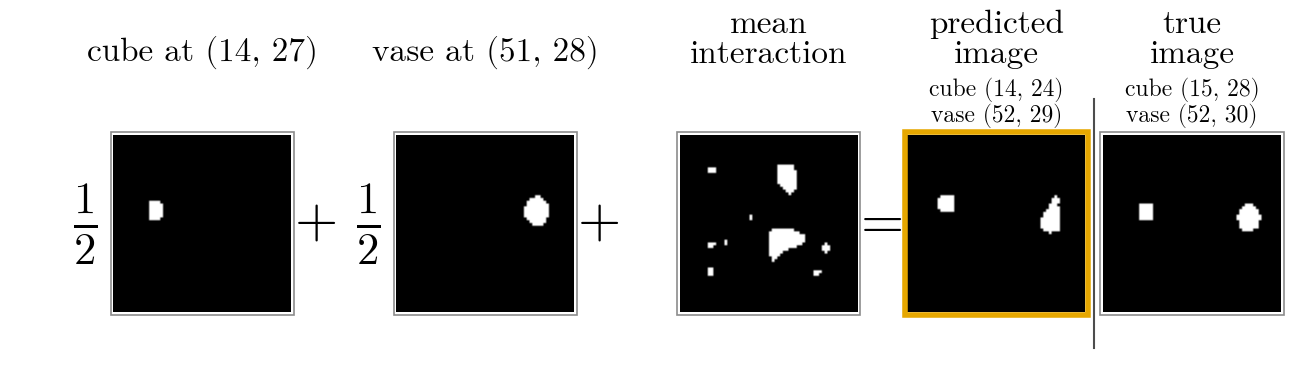

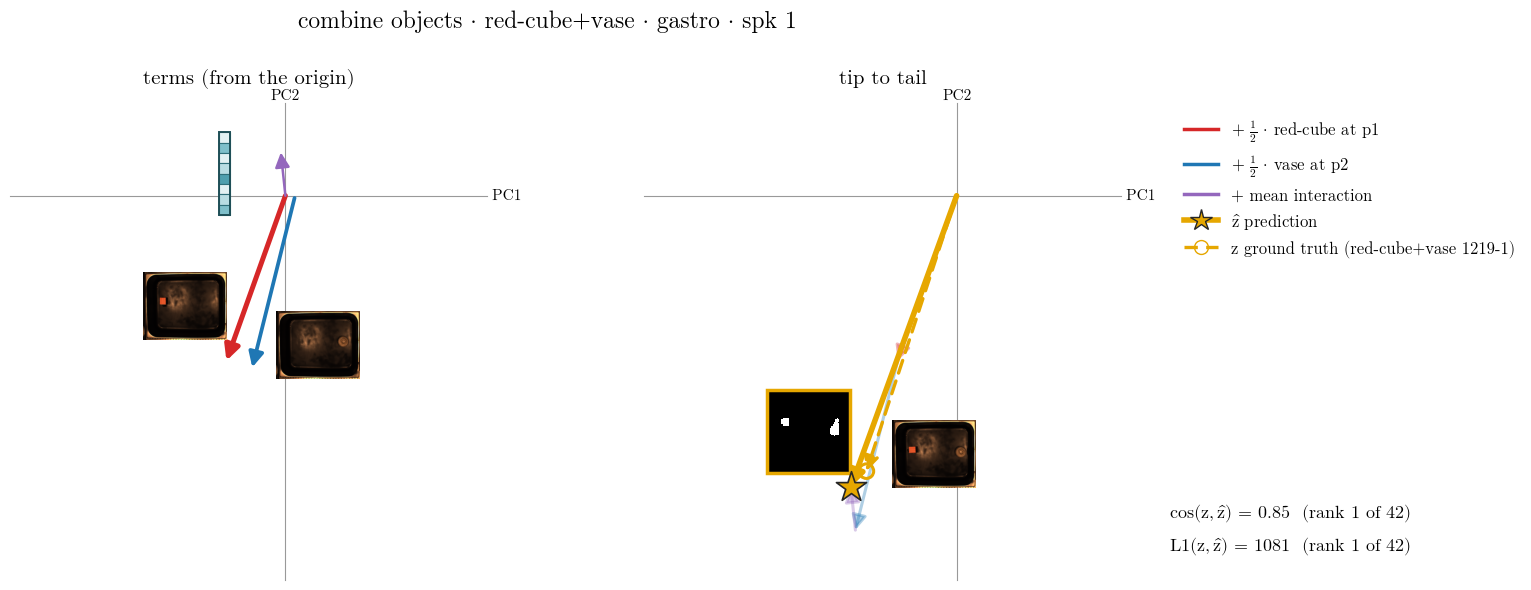

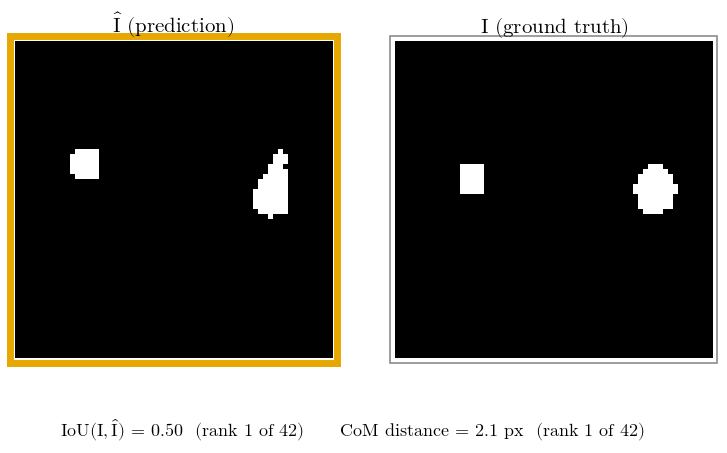

+ ½ red-cube at p1       121-1 · spk 1 · gastro · red-cube
+ ½ vase at p2           577-1 · spk 1 · gastro · vase
+   c                    mean red-cube+vase (n=41) − ½(mean red-cube (n=245) + mean vase (n=219)) in gastro · spk 1
=   target               1219-1 · spk 1 · gastro · red-cube+vase


In [35]:
row = top_combine.iloc[2]
plot_equation(row)
plot_equation_decoded(row)
plot_pca(row)
plot_layouts(row)
print_recordings(row)

### swap_objects_1

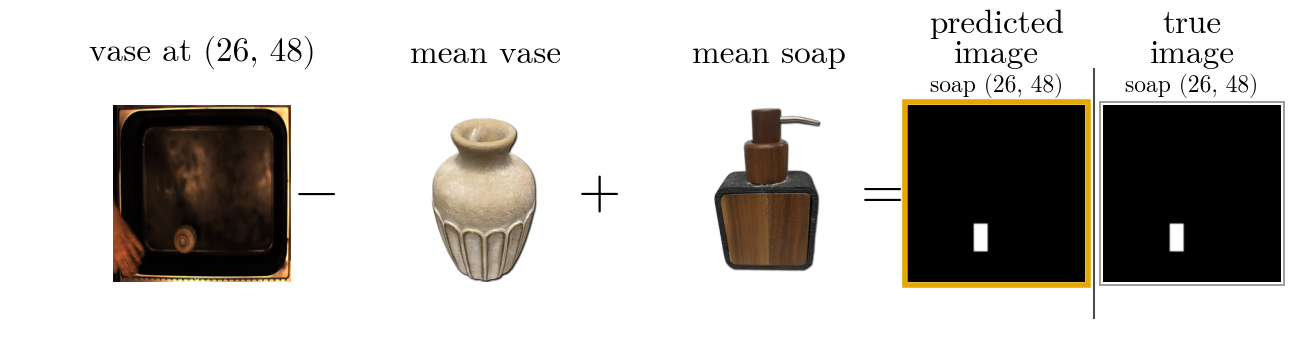

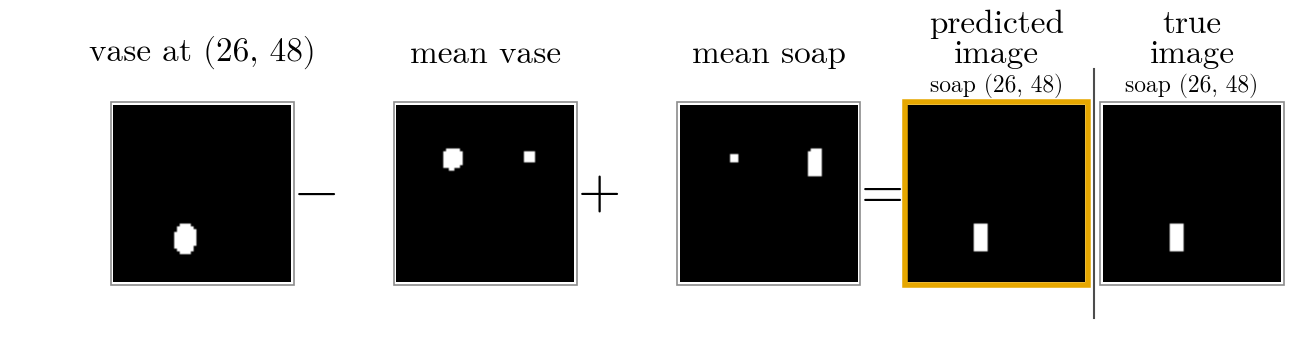

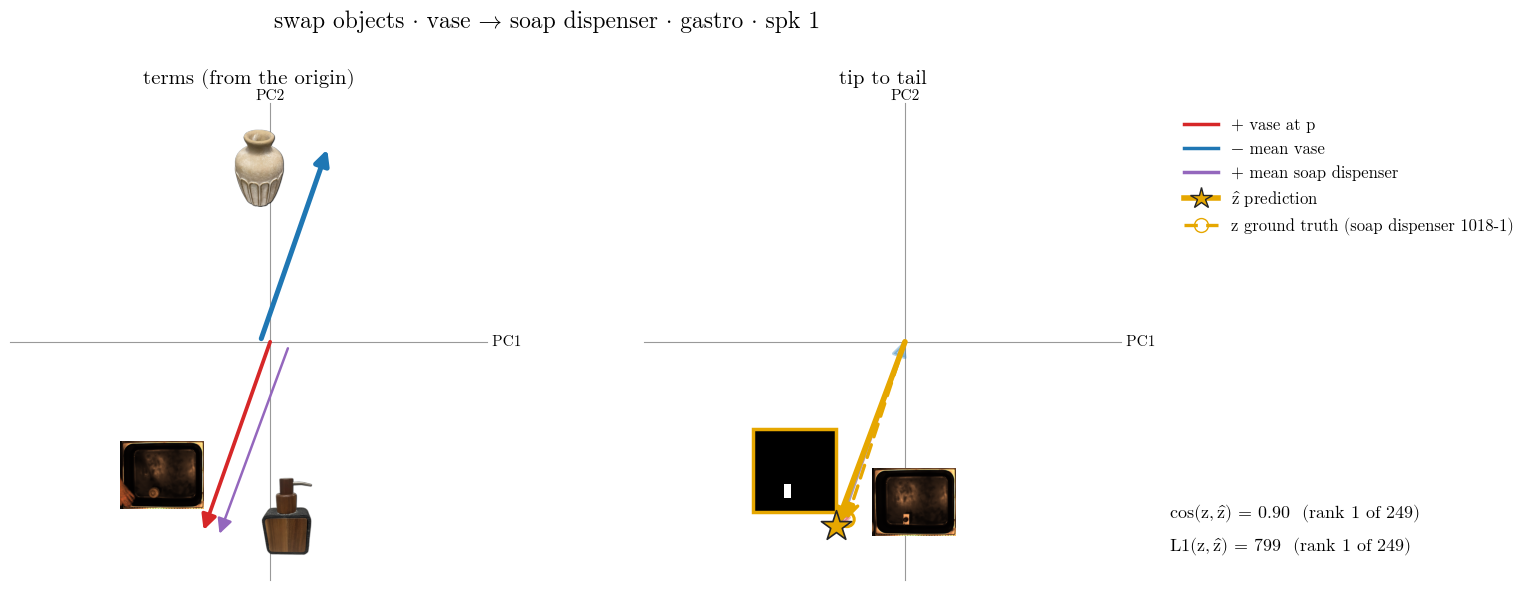

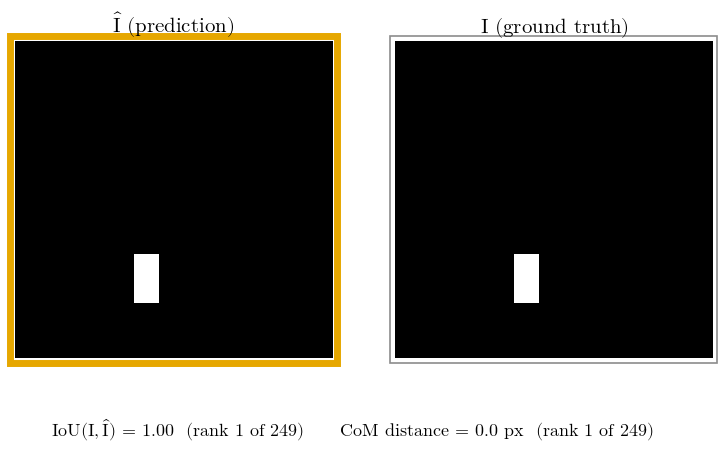

+   vase at p            442-1 · spk 1 · gastro · vase
−   mean vase            mean vase in gastro · spk 1 (n=219)
+   mean soap dispenser  mean soap dispenser in gastro · spk 1 (n=249)
=   target               1018-1 · spk 1 · gastro · soap dispenser


In [36]:
row = top_swap.iloc[0]
plot_equation(row)
plot_equation_decoded(row)
plot_pca(row)
plot_layouts(row)
print_recordings(row)

### swap_objects_2

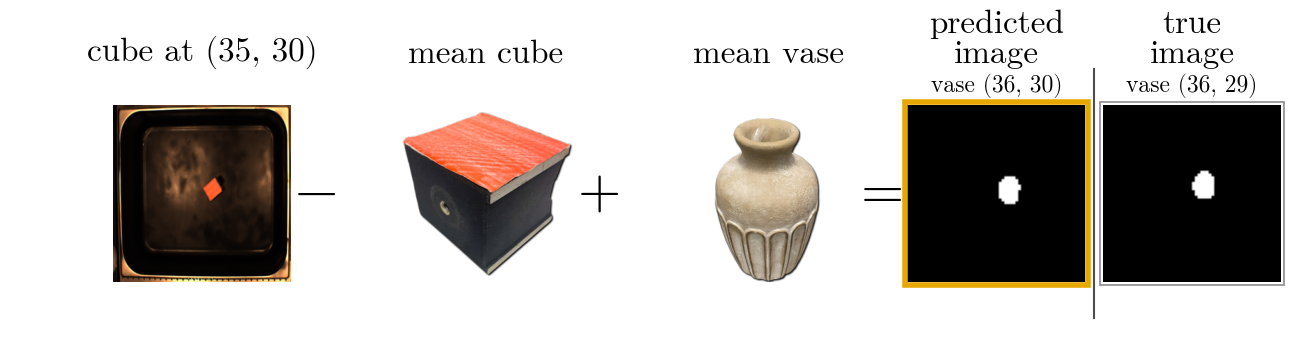

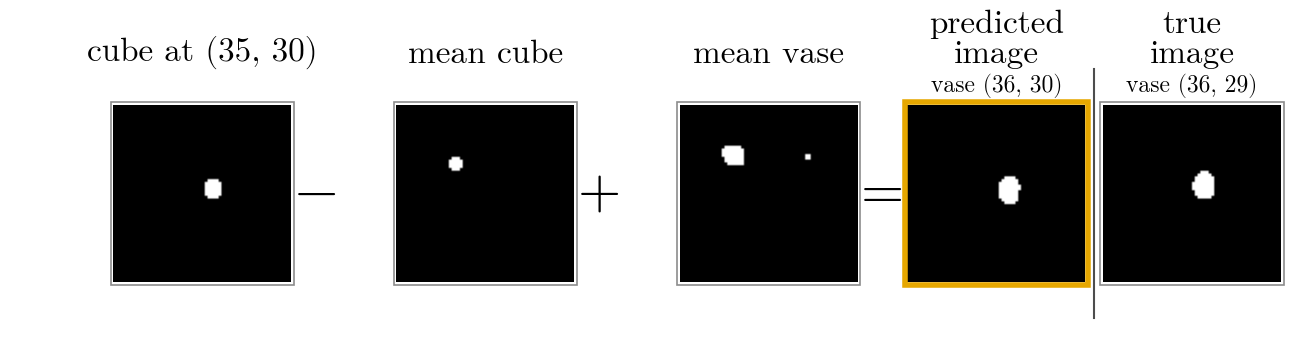

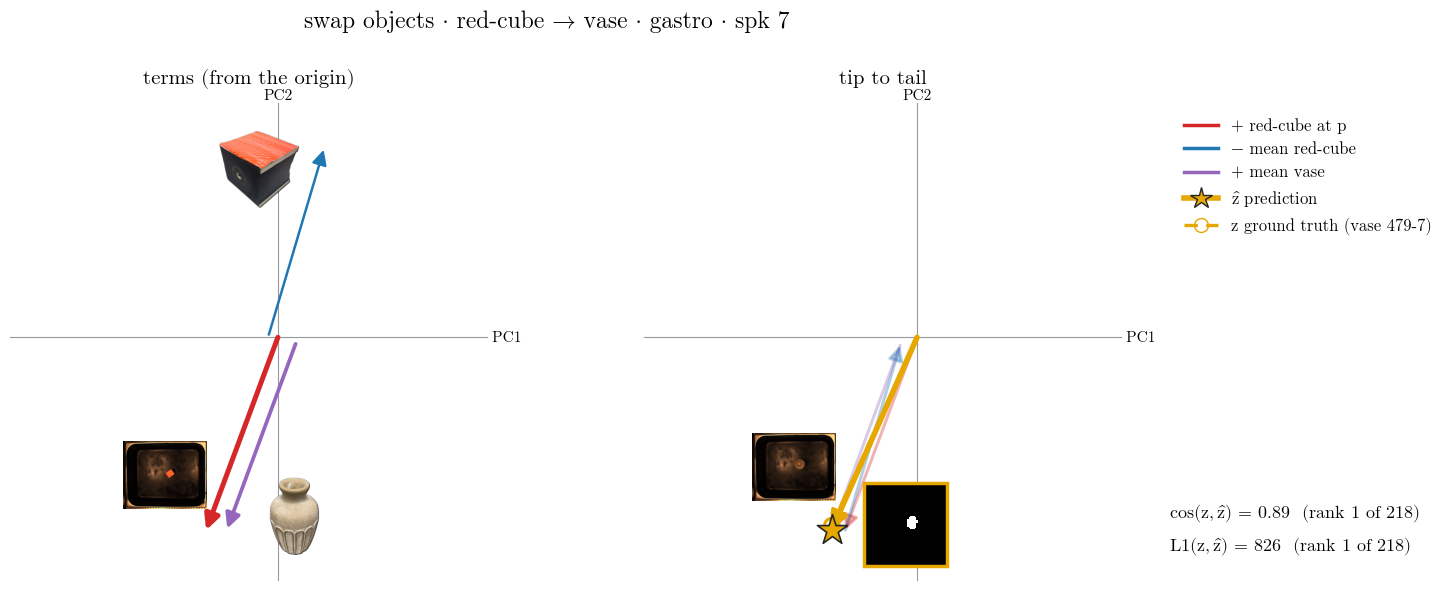

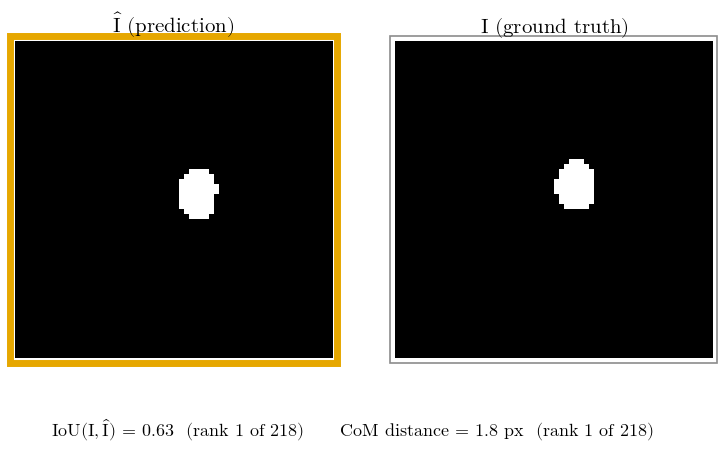

+   red-cube at p        271-7 · spk 7 · gastro · red-cube
−   mean red-cube        mean red-cube in gastro · spk 7 (n=245)
+   mean vase            mean vase in gastro · spk 7 (n=217)
=   target               479-7 · spk 7 · gastro · vase


In [37]:
row = top_swap.iloc[1]
plot_equation(row)
plot_equation_decoded(row)
plot_pca(row)
plot_layouts(row)
print_recordings(row)

### swap_objects_3

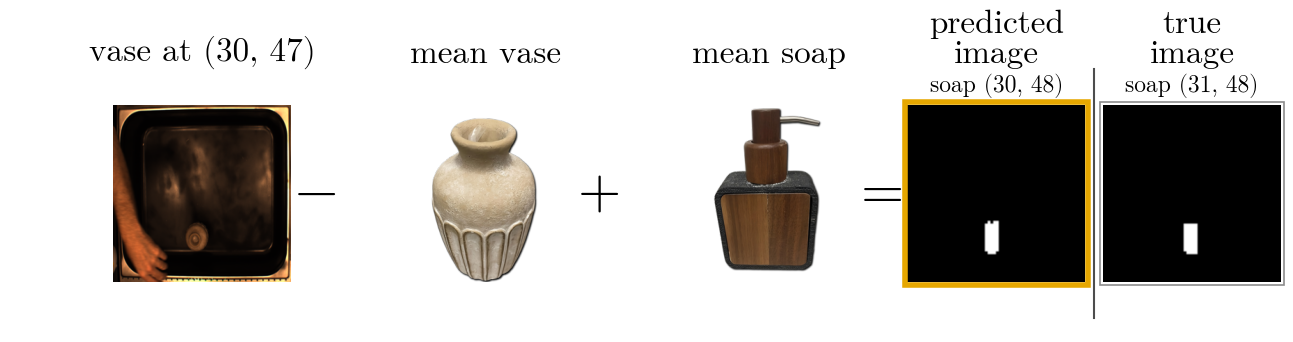

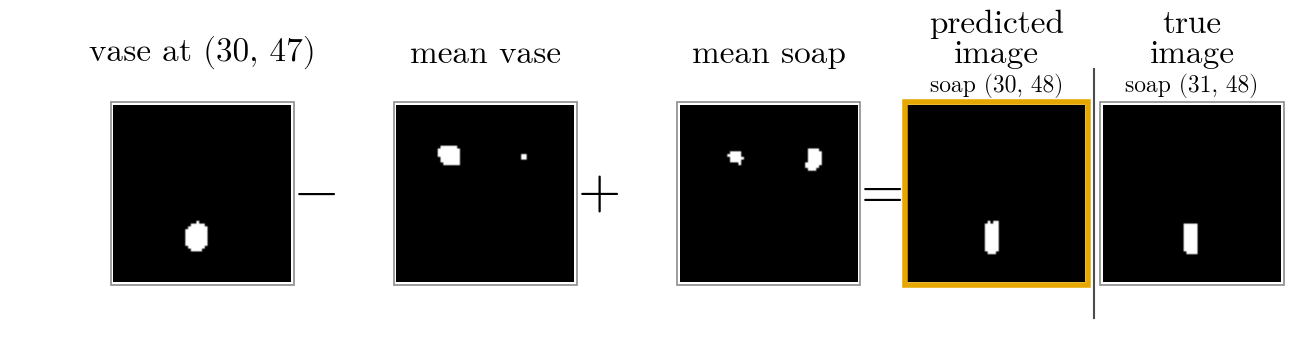

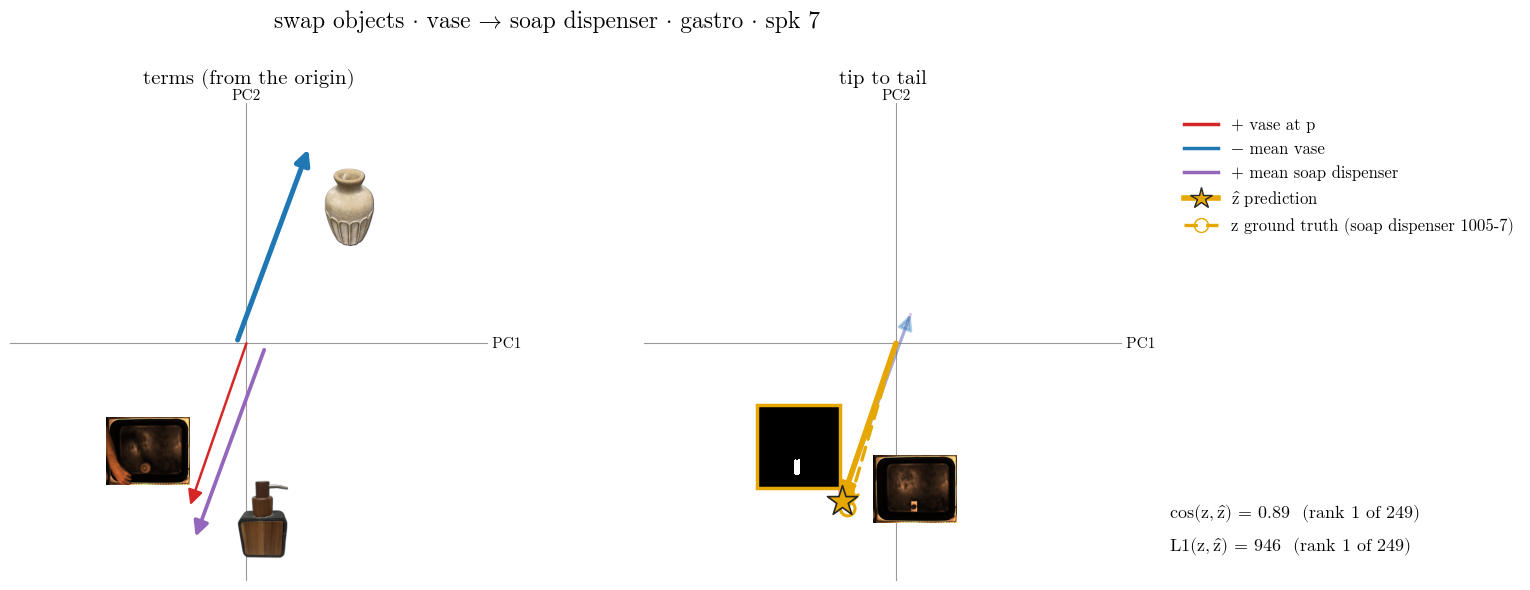

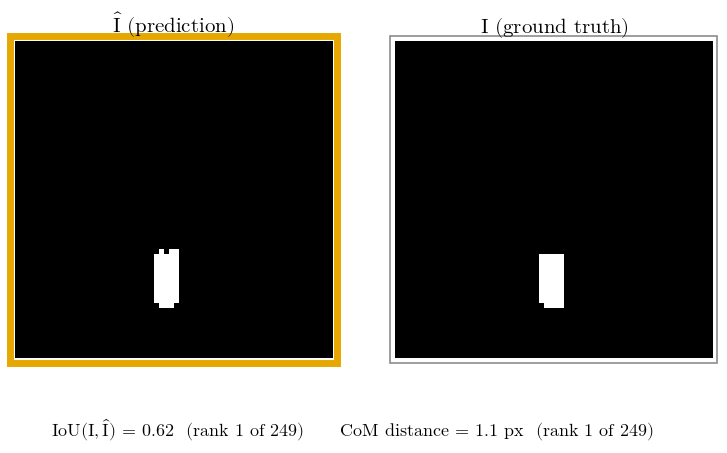

+   vase at p            469-7 · spk 7 · gastro · vase
−   mean vase            mean vase in gastro · spk 7 (n=218)
+   mean soap dispenser  mean soap dispenser in gastro · spk 7 (n=250)
=   target               1005-7 · spk 7 · gastro · soap dispenser


In [38]:
row = top_swap.iloc[2]
plot_equation(row)
plot_equation_decoded(row)
plot_pca(row)
plot_layouts(row)
print_recordings(row)

### combine_objects_nb139: the nb139 goal-combine best_1 recording (red-cube+vase · plastic · spk 3 · target 2788-3)
Here ½·obj1 + ½·obj2 comes from the single recording nearest each part (nb139 searched the K×K nearest pairs for the best one), so the two input recordings can differ from nb139's (2492-3, 2214-3).

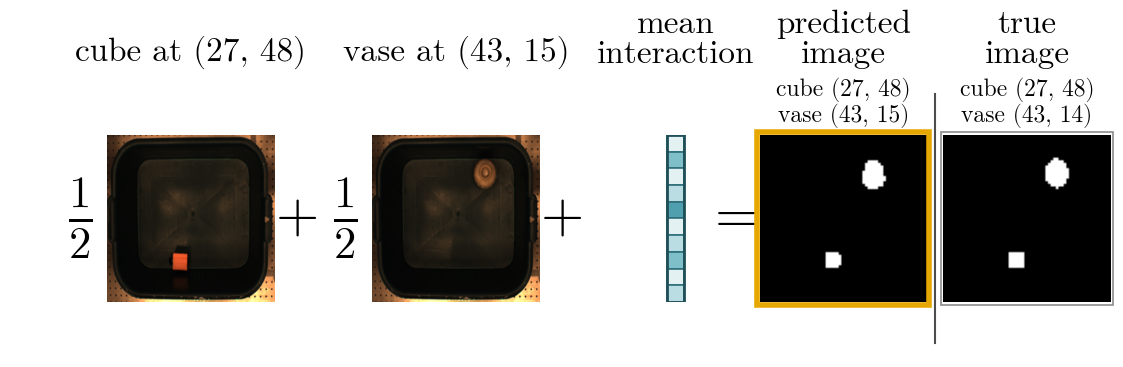

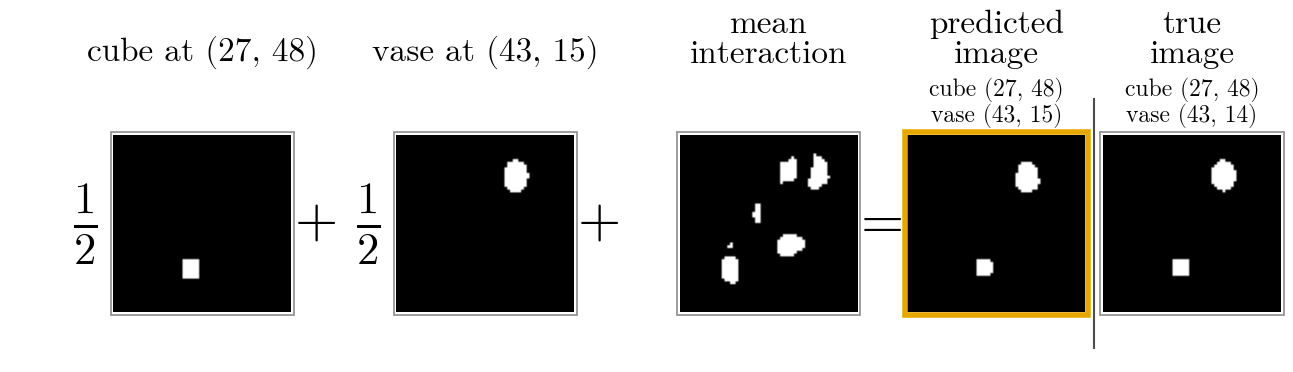

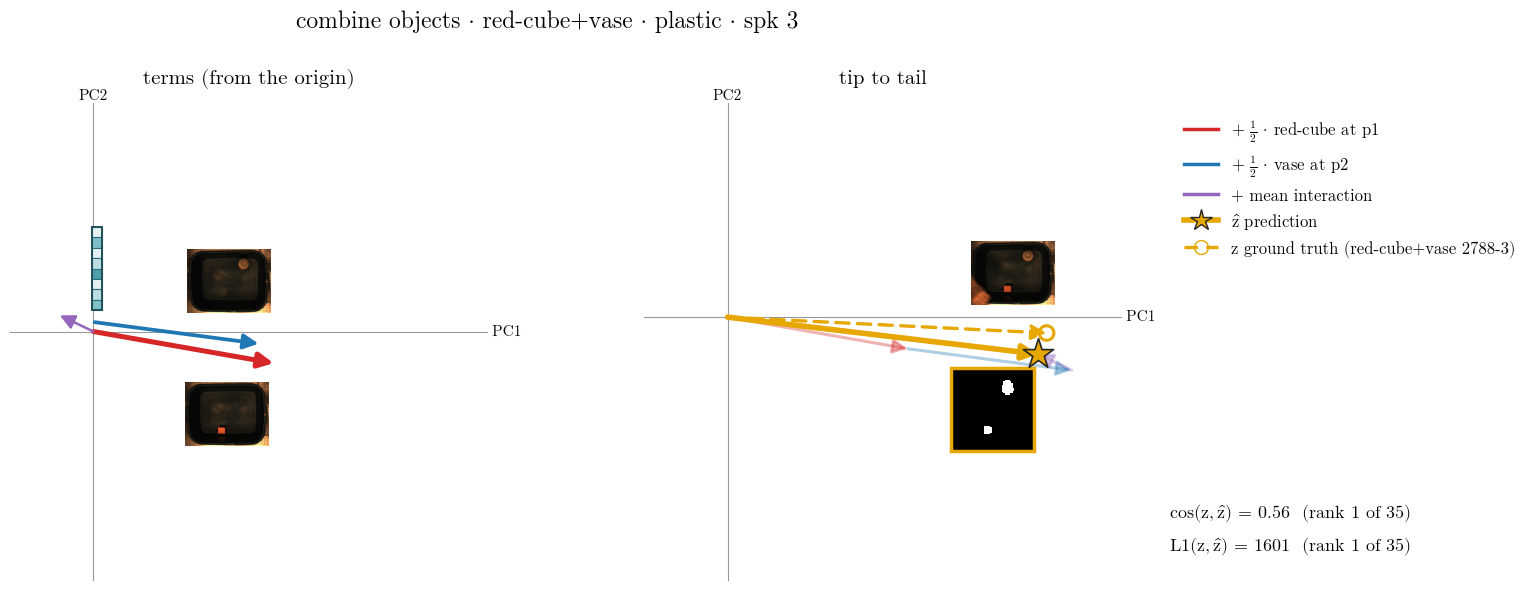

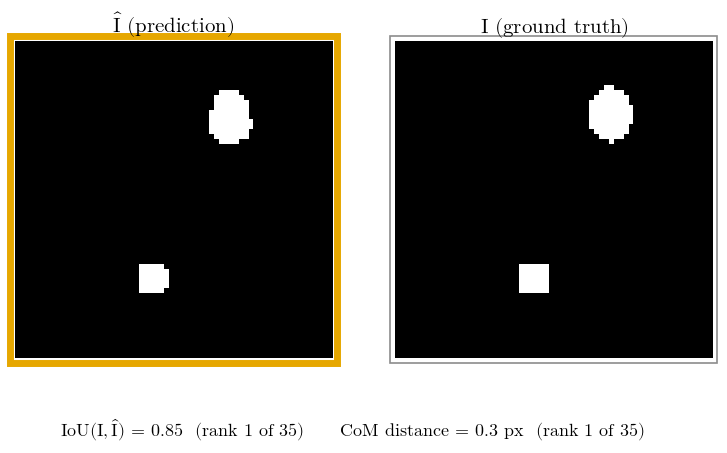

+ ½ red-cube at p1       2492-3 · spk 3 · plastic · red-cube
+ ½ vase at p2           2243-3 · spk 3 · plastic · vase
+   c                    mean red-cube+vase (n=34) − ½(mean red-cube (n=252) + mean vase (n=203)) in plastic · spk 3
=   target               2788-3 · spk 3 · plastic · red-cube+vase


In [39]:
is_nb139 = (search_combine.sid == "2788-3") & (search_combine.box == "plastic") & (search_combine.speaker == 3)
nb139_row = search_combine[is_nb139].iloc[0].copy()
nb139_row["fig_name"] = "combine_objects_nb139"
plot_equation(nb139_row)
plot_equation_decoded(nb139_row)
plot_pca(nb139_row)
plot_layouts(nb139_row)
print_recordings(nb139_row)

## Findings (decres-rescale-aug10-v1, fresh nb141 cache)

Every instance counts here, not just the best config. **exact** = the rank of the one target recording, with the other recordings at its position dropped (the main number). **any** = nb139's rule: a hit if any recording within SAME_POSITION_PX of p is the closest.

| task | box | n | rank@1 cos exact / any | rank@1 L2 exact / any | rank@1 IoU | mean IoU(I, Î) | median candidates |
|---|---|---|---|---|---|---|---|
| combine | plastic | 460 | .80 / .80 | .73 / .73 | .88 | .56 | 80 |
| combine | gastro | 338 | .61 / .61 | .52 / .52 | .60 | .34 | 71 |
| combine | cardboard | 705 | .31 / .31 | .21 / .21 | .49 | .34 | 94 |
| **combine** | all | 1503 | **.53 / .53** | **.44 / .44** | .63 | **.41** | |
| swap | plastic | 10309 | .29 / .44 | .28 / .44 | .70 | .69 | 251 |
| swap | gastro | 6914 | .25 / .37 | .26 / .38 | .60 | .63 | 248 |
| swap | cardboard | 11791 | .14 / .29 | .12 / .25 | .51 | .59 | 301 |
| **swap** | all | 29014 | **.22 / .36** | **.21 / .35** | .60 | **.63** | |

- **Exact vs any.** For combine the two rules agree: almost no other pair recording shares the same arrangement. For swap, "any" adds about .14, because 1–6 recordings of the target object sit within 2 px of p. nb139's .78 (plastic spk 7, red-cube → vase) used the "any" rule.
- **Combine objects** works for red-cube+vase in plastic: rank@1 cos .96, IoU .59. It is weak for green-cube+red-cube in cardboard (.17 / .25), where two red-cube recordings stand in for one green and one red cube.
- **Swap objects** rarely retrieves the exact latent (rank@1 about .2 of ~250), but the decoded layout is much better: IoU .63, IoU rank@1 .60. ẑ gets the object's place right more often than it lands on the exact latent.
- Cardboard is the weakest box for both tasks; plastic is the best.
- In the global 2-D PCA, z and ẑ almost overlap for every top instance. Two large terms dominate both PCs, so the PCA view flatters the analogy; the ranks are the honest number.
- The centred cosine is symmetric under reversal: A→B and B→A on the same two recordings get the same cos. `top_results()` keeps one of each mirrored pair.

## Paper equations: swap_objects_1 and the nb139 combine sample → svg next to this notebook

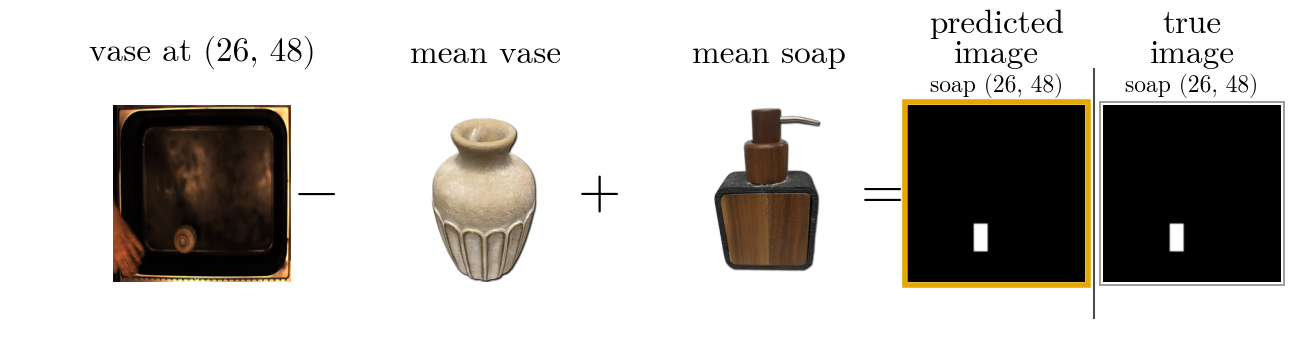

/home/ethantu/workspace/good-vibrations/figures/src/latent_tasks/swap_objects_equations.svg


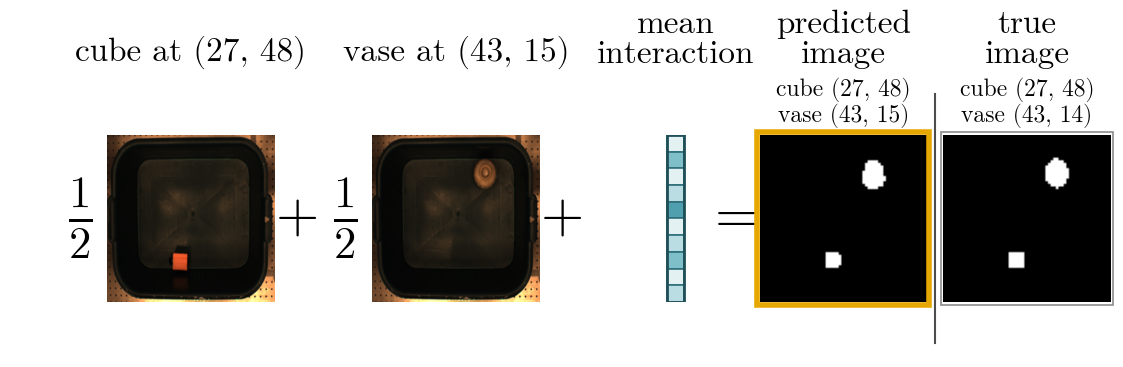

/home/ethantu/workspace/good-vibrations/figures/src/latent_tasks/combine_objects_equations.svg


In [40]:
for name, row in [("swap_objects", top_swap.iloc[0]), ("combine_objects", nb139_row)]:
    svg = plot_equation(row)  # plain input photos (outline=True adds the cyan label outline)
    shutil.copy(svg, HERE / f"{name}_equations.svg")
    print(HERE / f"{name}_equations.svg")

## Paper figure: both equations stacked (swap on top, combine below), short titles, no true image, plain frame, no dead space → figures/src/latent_tasks/both_equations.svg


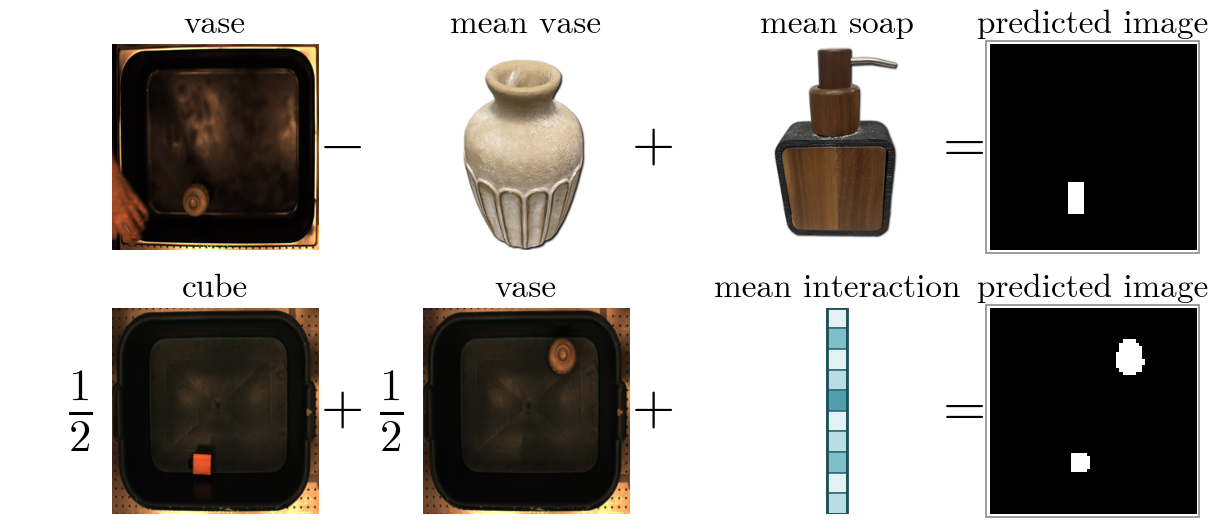

/home/ethantu/workspace/good-vibrations/figures/src/latent_tasks/both_equations.svg


In [41]:
def short_title(term):
    """A term's name on one line, without coordinates: "vase", "mean soap", "mean interaction"."""
    if term.kind == "photo":
        return SHORT_NAME[META.object[term.ref]]
    return term_title(term).replace("\n", " ")

def plot_equation_rows(rows, outline=False):
    """Several equations stacked so their columns line up: per term [operator, coefficient, picture], then [=, predicted image].
    Built for the paper: short titles and as little white space as possible."""
    terms_per_row = [rebuild(row).terms for row in rows]
    n_terms = max(len(terms) for terms in terms_per_row)
    ratios = []
    for i in range(n_terms):  # a column is as wide as its widest picture, so the = and predicted images line up
        widths = [LATENT_SLOT_WIDTH if terms[i].kind == "interaction" else 1 for terms in terms_per_row if i < len(terms)]
        ratios += [.2, .26, max(widths)]
    ratios += [.2, 1]
    fig, grid = plt.subplots(len(rows), len(ratios), figsize=(2.75 * sum(ratios), 3.05 * len(rows)),
                             gridspec_kw=dict(width_ratios=ratios, wspace=0, hspace=.28))
    titles = []  # (row index, axes, text)
    for r, (row, terms) in enumerate(zip(rows, terms_per_row)):
        axes = grid[r]
        for ax in axes:
            ax.set_axis_off()
        draw_operators(axes, terms)
        for i, term in enumerate(terms):
            ax = axes[3 * i + 2]
            if term.kind == "interaction":
                draw_latent_column(ax)
            elif term.kind == "photo":
                draw_photo(ax, term.ref, outline)
                ax.set_box_aspect(1)
            else:
                draw_icon(ax, term.ref)
                ax.set_box_aspect(1)
            titles.append((r, ax, short_title(term)))
        equals, pred_ax = axes[3 * n_terms:]
        equals.text(.5, .5, "=", ha="center", va="center", fontsize=OPERATOR_FS)
        draw_mask(pred_ax, predicted_mask(row))  # plain grey frame, like every other layout
        pred_ax.set_box_aspect(1)
        titles.append((r, pred_ax, "predicted image"))
    fig.canvas.draw()
    for r in range(len(rows)):  # one title baseline per row, just above that row's tallest picture
        row_titles = [(ax, text) for i, ax, text in titles if i == r]
        top = max(ax.get_position().y1 for ax, _ in row_titles) + .008
        for ax, text in row_titles:
            box = ax.get_position()
            fig.text((box.x0 + box.x1) / 2, top, text, ha="center", va="bottom", fontsize=TITLE_FS, linespacing=1.0)
    return fig

fig = plot_equation_rows([top_swap.iloc[0], nb139_row])
fig.savefig(HERE / "both_equations.svg", bbox_inches="tight", pad_inches=.02)
plt.show()
plt.close(fig)
print(HERE / "both_equations.svg")

## Paper numbers: how often the ground truth is rank 1, over all edits and in the box and speaker of the two figure examples
The paper reports IoU rank 1 over all boxes (combine 63% of 1,503, swap 60% of 29,014). The 96% for cube + vase in plastic is the cosine rank; by IoU it is 94% of 140.

In [ ]:
def rank1_line(label, table):
    n = len(table)
    iou_hits = int((table.rank_iou == 1).sum())
    cos_hits = int((table.rank_cos == 1).sum())
    chance = (1 / table.n_candidates).mean()
    candidates = int(table.n_candidates.median())
    print(f"  {label:44s} n = {n:>6,}   IoU rank 1: {iou_hits:>6,} ({iou_hits / n:5.1%})   "
          f"cos rank 1: {cos_hits:>6,} ({cos_hits / n:5.1%})   chance {chance:4.1%}   median candidates {candidates}")

def paper_numbers(task_name, table, example):
    print(f"{task_name}: one row = one edit, ranked among the target object's samples in the same box and speaker")
    rank1_line("all boxes", table)
    for box in ["plastic", "gastro", "cardboard"]:
        rank1_line(box, table[table.box == box])
    in_box = table.box == example.box
    in_speaker = table.speaker == example.speaker
    same_objects = (table.obj1 == example.obj1) & (table.obj2 == example.obj2)
    objects = f"{example.obj1} -> {example.obj2}"
    print(f"  figure example: sample {example.sid}, {example.box}, speaker {example.speaker}, {objects}, "
          f"IoU {example.iou:.2f}, IoU rank {example.rank_iou} of {example.n_candidates}, cos rank {example.rank_cos}")
    rank1_line(f"{example.box}, speaker {example.speaker}", table[in_box & in_speaker])
    rank1_line(f"{example.box}, {objects}", table[in_box & same_objects])
    rank1_line(f"{example.box}, speaker {example.speaker}, {objects}", table[in_box & in_speaker & same_objects])
    print()

paper_numbers("combine objects", search_combine, nb139_row)
paper_numbers("swap objects", search_swap, top_swap.iloc[0])

combine objects: one row = one edit, ranked among the target object's samples in the same box and speaker
  all boxes                                    n =  1,503   IoU rank 1:    949 (63.1%)   cos rank 1:    790 (52.6%)   chance 1.5%   median candidates 80
  plastic                                      n =    460   IoU rank 1:    404 (87.8%)   cos rank 1:    366 (79.6%)   chance 1.7%   median candidates 80
  gastro                                       n =    338   IoU rank 1:    202 (59.8%)   cos rank 1:    205 (60.7%)   chance 1.8%   median candidates 71
  cardboard                                    n =    705   IoU rank 1:    343 (48.7%)   cos rank 1:    219 (31.1%)   chance 1.1%   median candidates 94
  figure example: sample 2788-3, plastic, speaker 3, red-cube -> red-cube+vase, IoU 0.85, IoU rank 1 of 35, cos rank 1
  plastic, speaker 3                           n =    115   IoU rank 1:    104 (90.4%)   cos rank 1:     92 (80.0%)   chance 1.7%   median candidates 80
  plastic,